# Objectif 

Analyse de la portion 1 extraite via le code acouplane_select_and_extract_portion1.ipynb

Date de création : 07/10/2026

In [1]:
import os
import sys
import glob
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.io import loadmat
from matplotlib.lines import Line2D
from datetime import datetime, timedelta

In [2]:
if os.name == "nt":  # Windows
    ROOT_PROGRAM = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd"
else:  # Linux
    ROOT_PROGRAM = "/home/program/ubf_tools"
sys.path.append(ROOT_PROGRAM)

from misc import equivalent_celerity
from publication.publication_figure import set_subfigures_abc_labels, color
from real_data_analysis.acouplane.src.acouplane_cst import *
from real_data_analysis.acouplane.src.acouplane_utils import *


# Chargement des données 

Les données sont stockées au format netcdf sous la forme d'un arbre (xarray DataTree) et regroupe l'ensemble des données associées à la portion d'intérêt. 

In [3]:
portion_id = 1
fpath = f"{ACOUPLANE_PORTION_NC_ROOT_FPATH}_{portion_id}.nc"
portion = xr.open_datatree(fpath)
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                   ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:50...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 968B 2026-02-25T09:5...
│   │         * src_datetime           (src_datetime) datetime64[ns] 3kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 9kB ...
│   │           atl_lat                (atl_datetime) float64 9kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 509kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 3kB ...
│   │           tir_src_lon            (src_datetime) float64 3kB ...
│   │           tir_src_lat            (src_datetime) float64 3kB ...
│   │           tir_vessel_lon         (src_datetime) float64 3kB ...
│   │           tir_vessel_lat         (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 22kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                   ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:42...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 488B 2026-02-25T00:4...
│   │         * src_datetime           (src_datetime) datetime64[ns] 2kB 2026-02-25T00:42...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B ...
│   │           rcv_lat                (rcv_id) float64 56B ...
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 5kB ...
│   │           atl_lat                (atl_datetime) float64 5kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 257kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 2kB ...
│   │           tir_src_lon            (src_datetime) float64 2kB ...
│   │           tir_src_lat            (src_datetime) float64 2kB ...
│   │           tir_vessel_lon         (src_datetime) float64 2kB ...
│   │           tir_vessel_lat         (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 11kB ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Ouest/Est
│   │           section_id:               1
│   ├── Group: /position/oe2
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,

# Rappel de la position de la portion 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

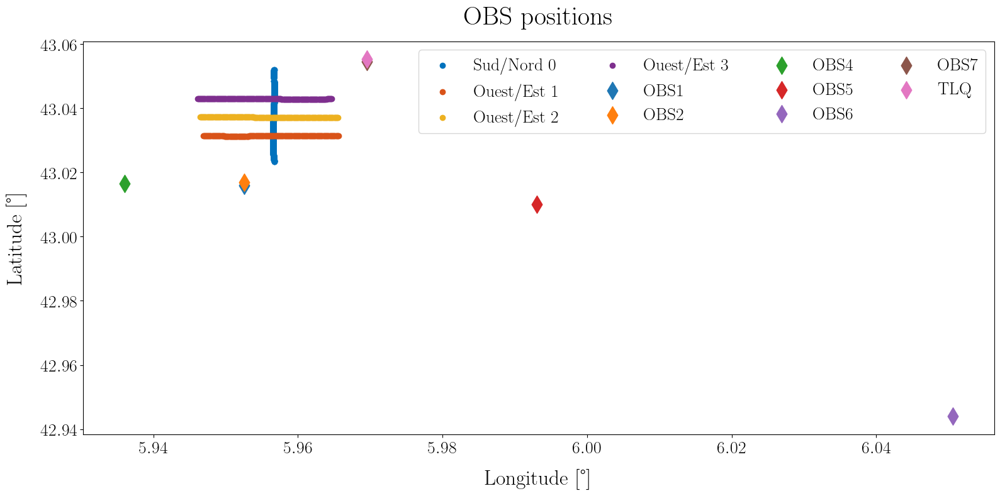

In [4]:
plot_portion_tir_pos(portion_tree=portion)

# Correction de la position des OBS

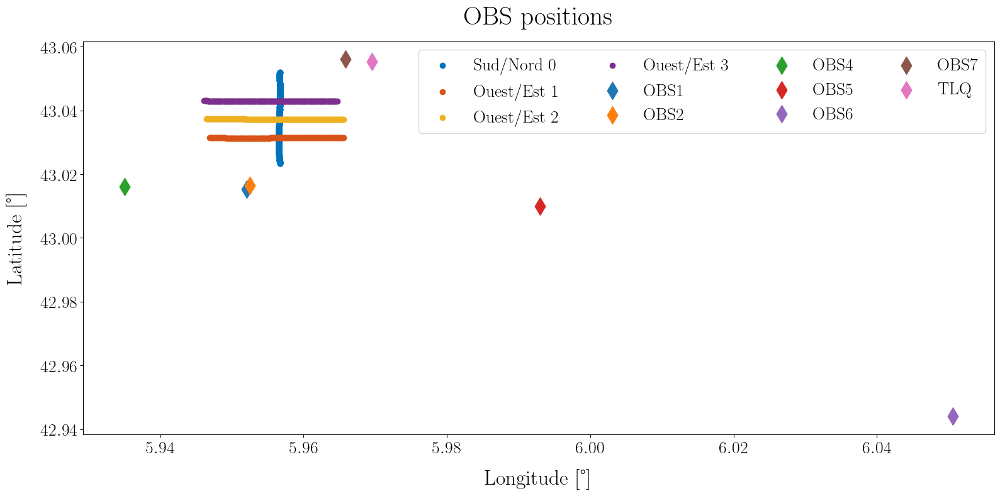

In [5]:
apply_obs_pos_correction = True 

if apply_obs_pos_correction:
    apply_rcv_position_correction_to_portion(portion_tree=portion)
    portion
    plot_portion_tir_pos(portion_tree=portion)

# Visualisation des données de pression

## Signaux

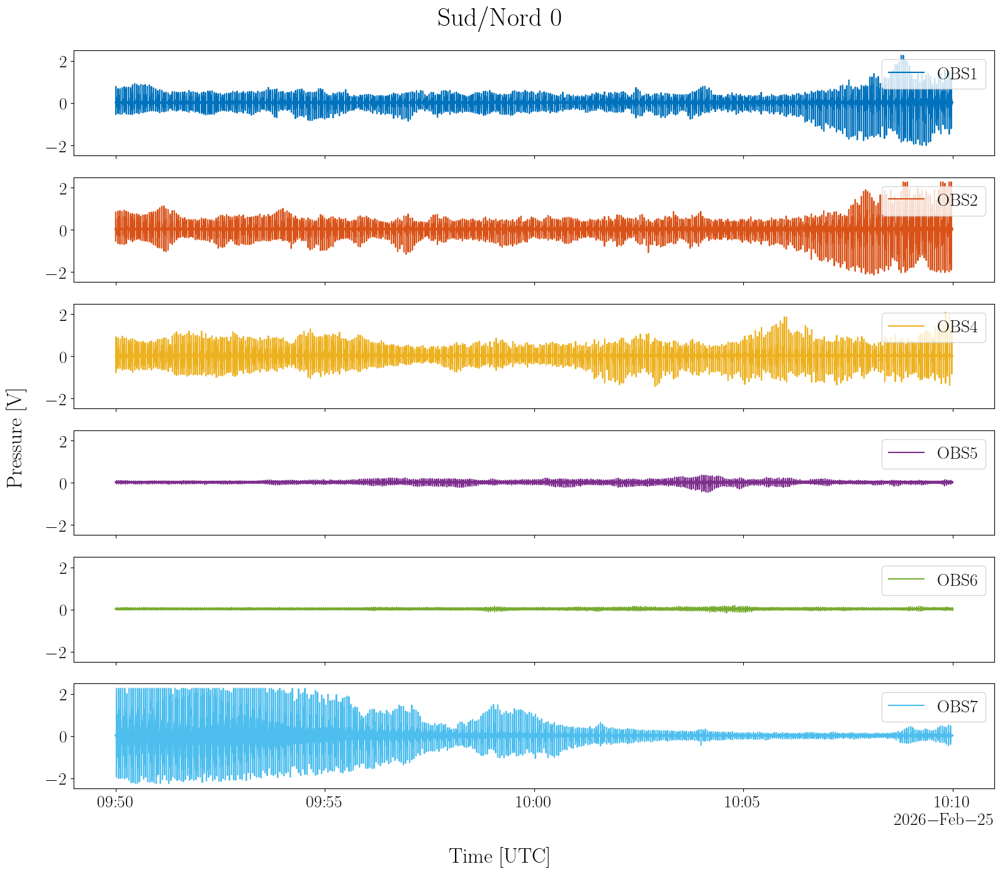

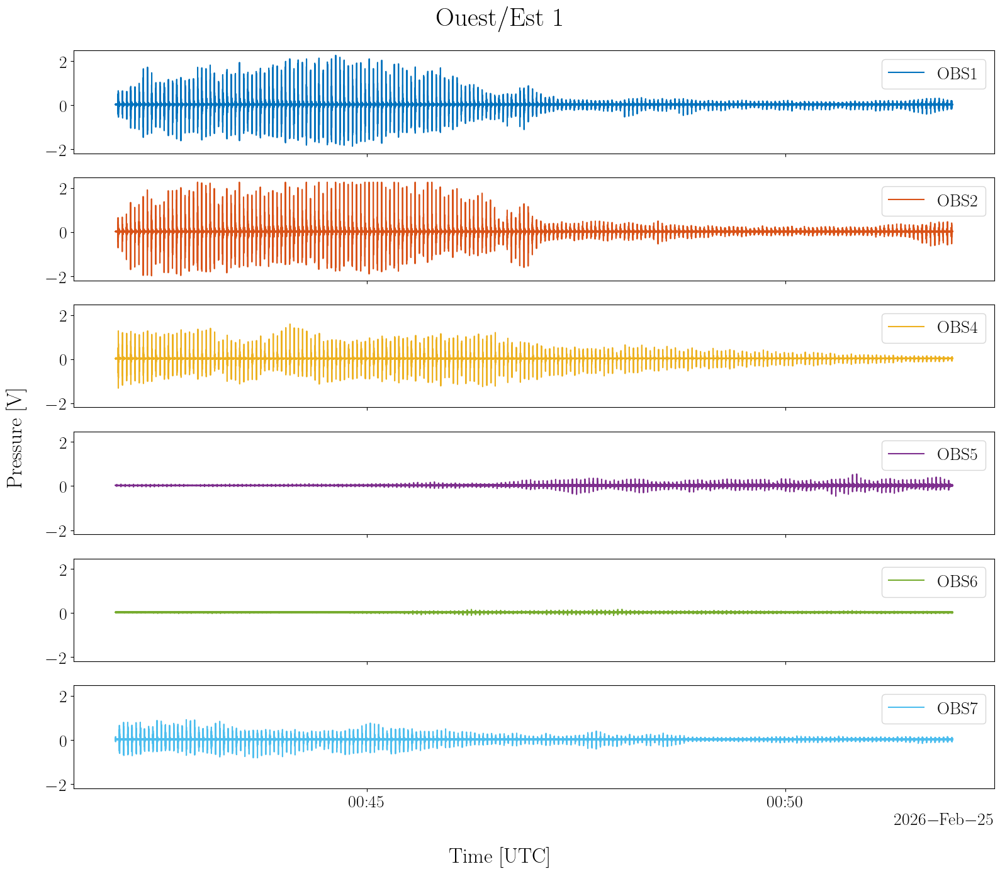

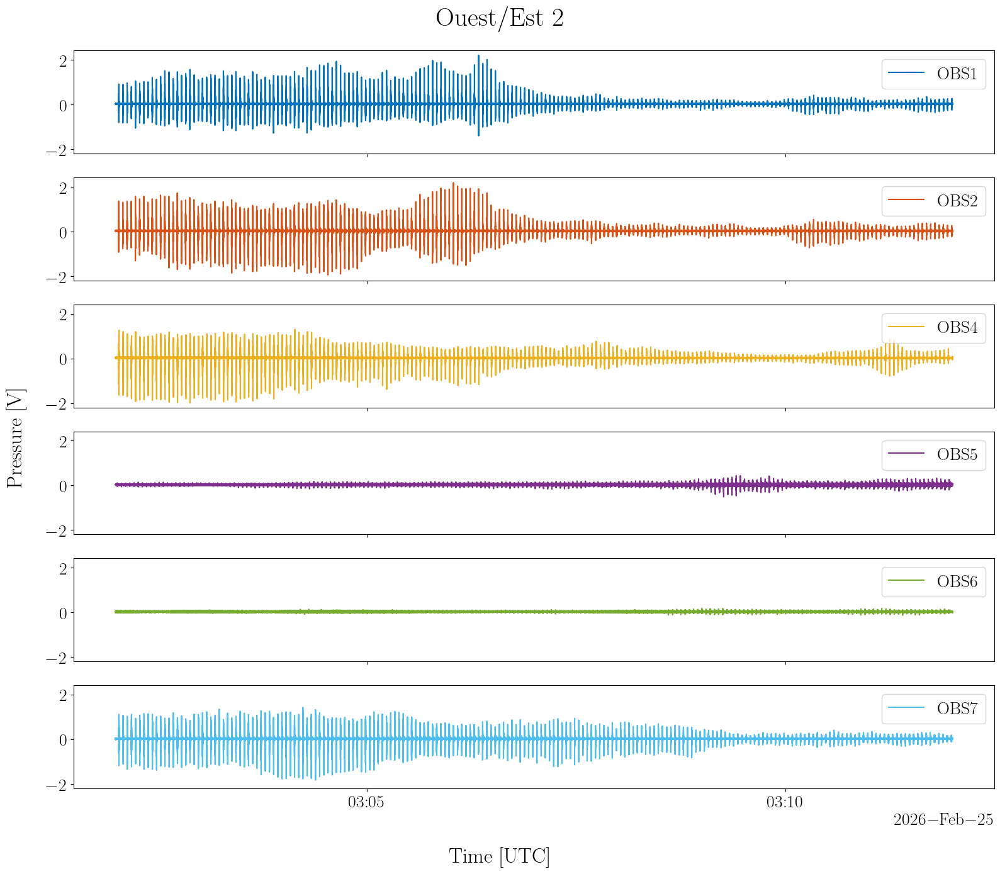

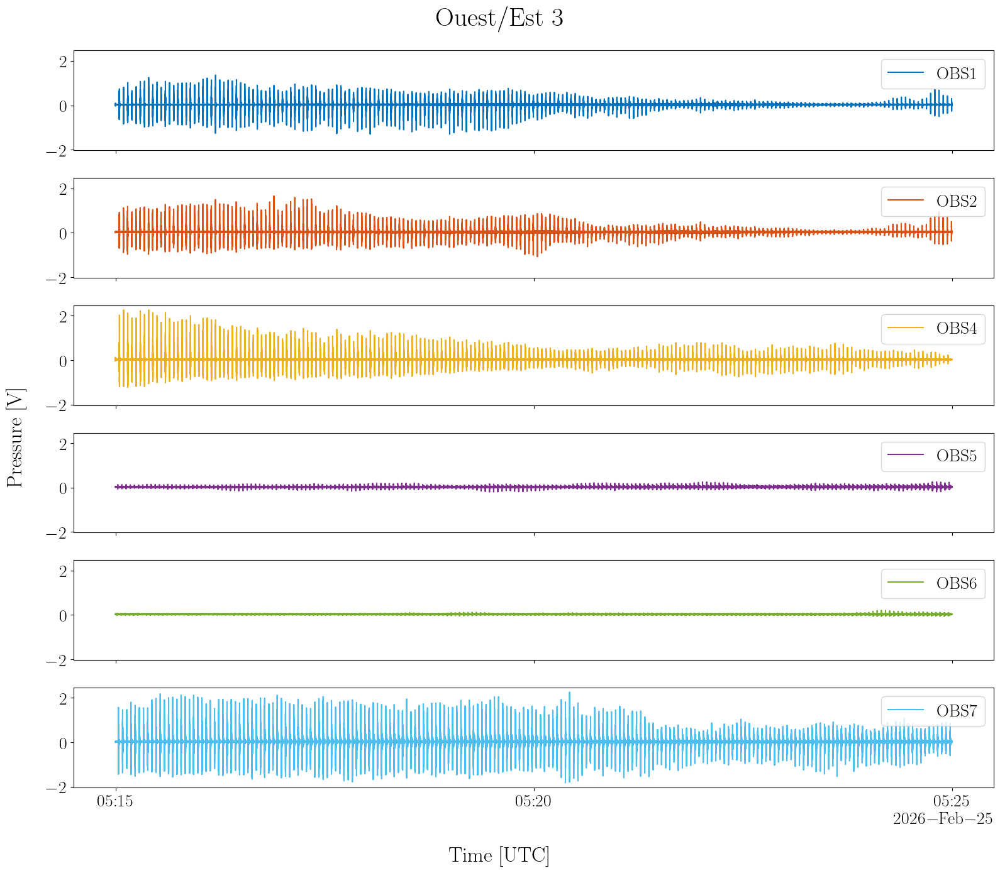

In [6]:
# Plot 
single_fig = False
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_pressure_section(ds_pressure_section=ds_pressure_section, single_fig=single_fig)
    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    plt.show()

## Spectrogrames 

**Remarque** : l'amplitude des cannons décroit avec le temps avant de revenir à l'amplitude de départ. Ce comportement nominal des cannons à air comprimé se traduit par une modulation d'amplitude des tirs visibles sur les spectrogrames ci dessous.    

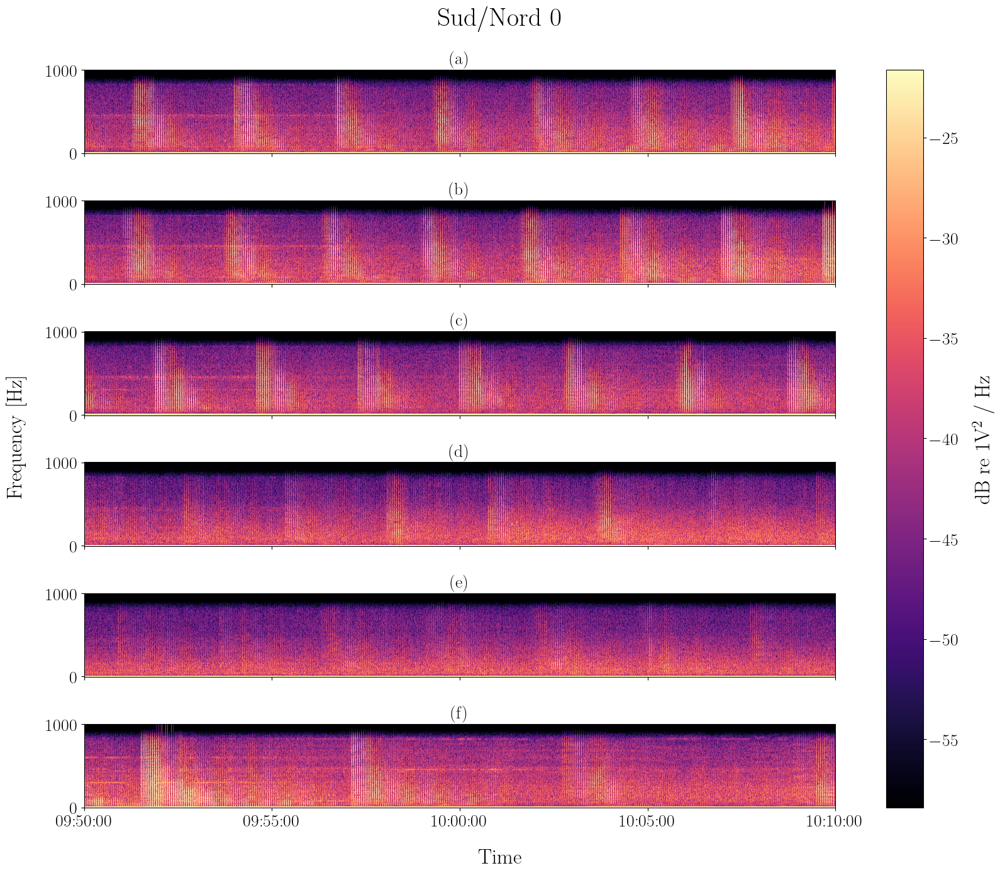

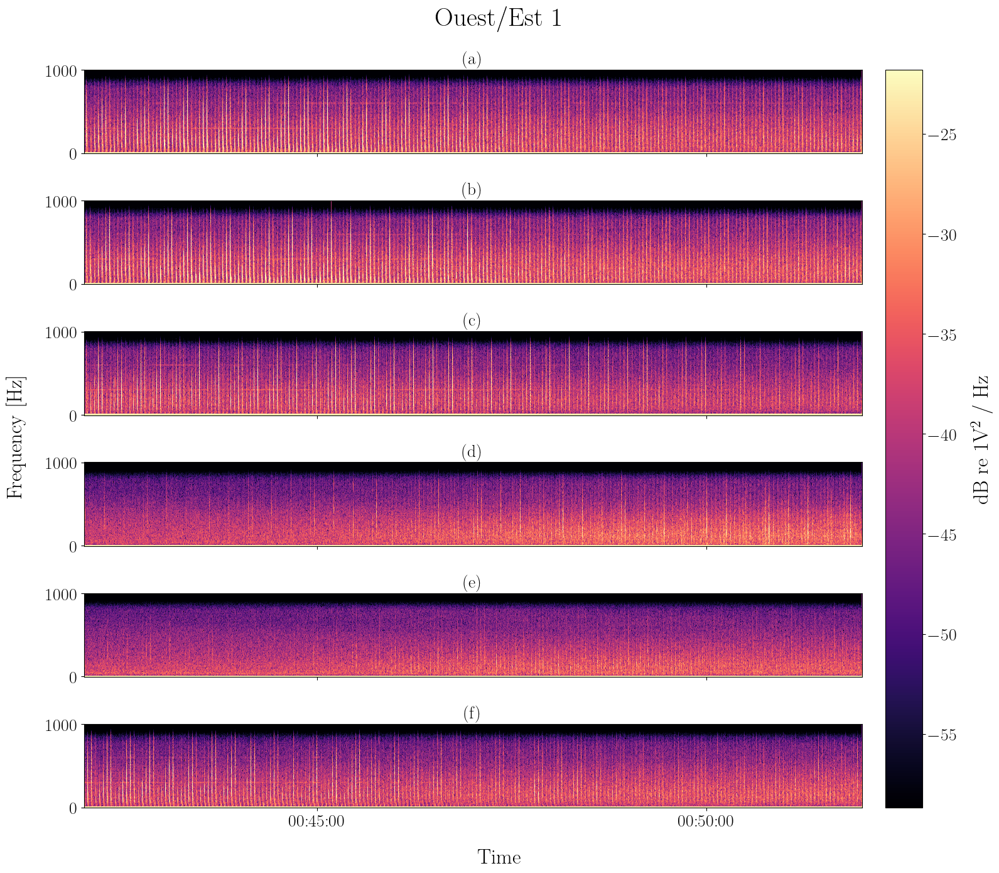

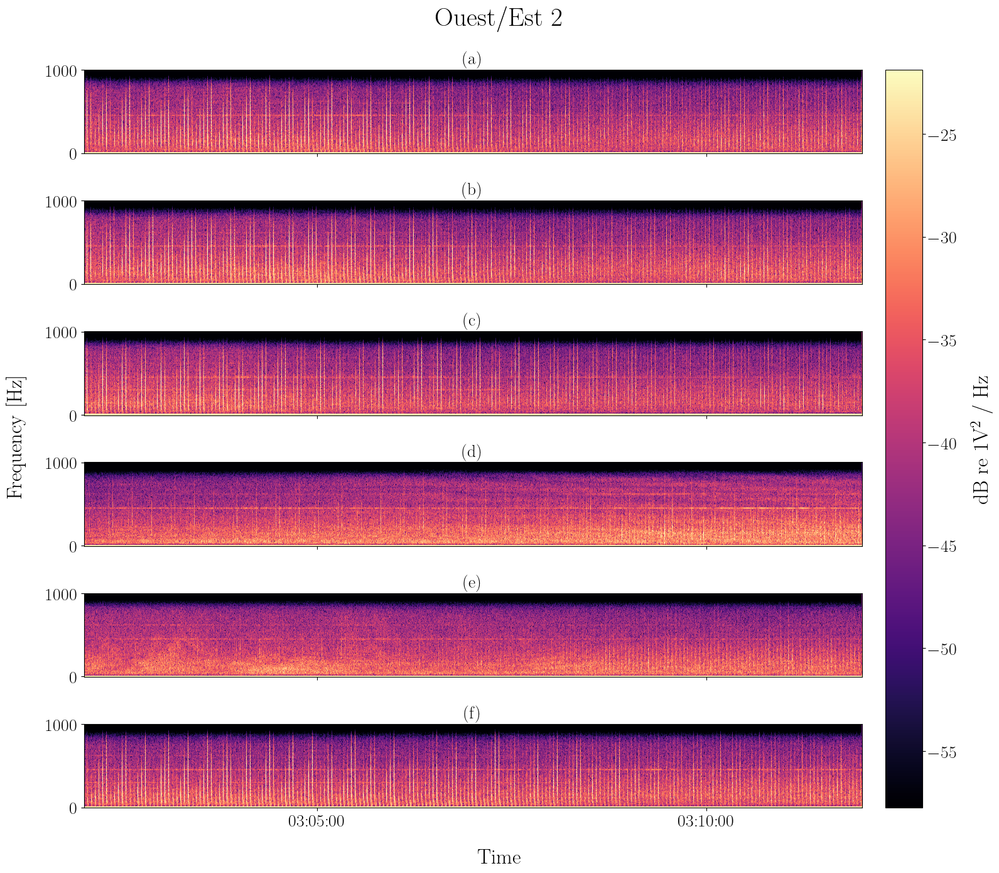

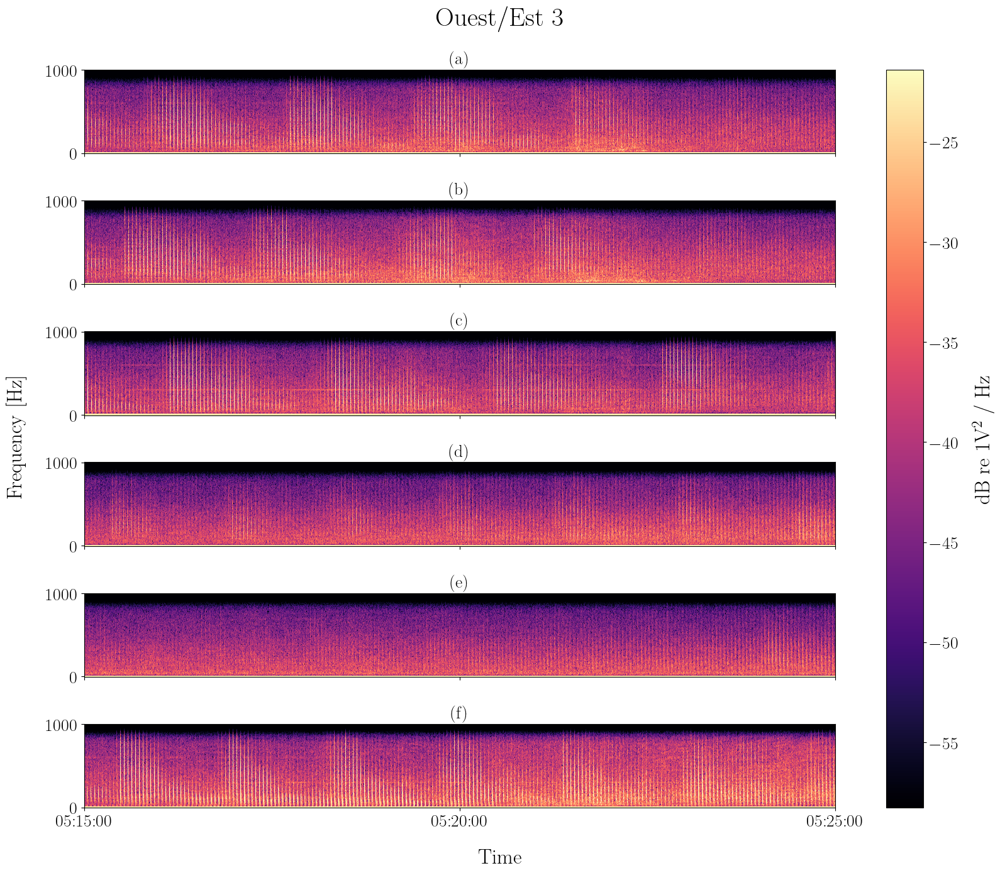

In [7]:
# Plot 
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()
    fig, axs = plot_spectrogram_section(ds_pressure_section, nperseg=2**8, noverlap=2**7, cmap="magma")
    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    plt.show()

# Calcul des grandeurs signantes 

In [8]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                   ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:50...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 968B 2026-02-25T09:5...
│   │         * src_datetime           (src_datetime) datetime64[ns] 3kB 2026-02-25T09:50...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B 5.952 5.953 5.935 ... 5.966 5.97
│   │           rcv_lat                (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 9kB ...
│   │           atl_lat                (atl_datetime) float64 9kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 509kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 3kB ...
│   │           tir_src_lon            (src_datetime) float64 3kB 5.957 5.957 ... 5.957
│   │           tir_src_lat            (src_datetime) float64 3kB 43.05 43.05 ... 43.02
│   │           tir_vessel_lon         (src_datetime) float64 3kB ...
│   │           tir_vessel_lat         (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 22kB 4.11e+03 ... 3...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                   ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                 (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime           (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:42...
│   │         * ais_datetime           (ais_datetime) datetime64[ns] 488B 2026-02-25T00:4...
│   │         * src_datetime           (src_datetime) datetime64[ns] 2kB 2026-02-25T00:42...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/14)
│   │           rcv_lon                (rcv_id) float64 56B 5.952 5.953 5.935 ... 5.966 5.97
│   │           rcv_lat                (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion          (rcv_id) int16 14B ...
│   │           atl_lon                (atl_datetime) float64 5kB ...
│   │           atl_lat                (atl_datetime) float64 5kB ...
│   │           ais_lon                (mmsi, ais_datetime) float64 257kB ...
│   │           ...                     ...
│   │           tir_ECOS               (src_datetime) int64 2kB ...
│   │           tir_src_lon            (src_datetime) float64 2kB 5.947 5.947 ... 5.966
│   │           tir_src_lat            (src_datetime) float64 2kB 43.03 43.03 ... 43.03
│   │           tir_vessel_lon         (src_datetime) float64 2kB ...
│   │           tir_vessel_lat         (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist  (rcv_id, src_datetime) float64 11kB 1.849e+03 ... ...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1

## Extraction de chaques émissions

### Calcul de la célérité équivalente 

In [9]:
celerity = xr.open_datatree(ACOUPLANE_CELERITY_NC_FPATH)
celerity

<xarray.DataTree>
Group: /
├── Group: /T0_00006
│       Dimensions:      (depth: 322)
│       Coordinates:
│         * depth        (depth) float64 3kB 0.0 0.6301 1.26 1.89 ... 198.8 199.4 200.0
│       Data variables:
│           temperature  (depth) float64 3kB ...
│           celerity     (depth) float64 3kB ...
│       Attributes:
│           longitude:                 5.9519785
│           latitude:                  43.0480848
│           surface_temperatude_degC:  14.2
│           pression_atmo_hPa:         1021.0
│           salinity_ppt:              37.5
├── Group: /T0_00007
│       Dimensions:      (depth: 253)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 156.2 156.8 157.4
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 5.9523738
│           latitude:                  43.0173035
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1020.2
│           salinity_ppt:              37.5
├── Group: /T0_00012
│       Dimensions:      (depth: 160)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 98.39 99.02 99.64
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 5.9512852
│           latitude:                  43.0566788
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1025.6
│           salinity_ppt:              37.5
├── Group: /T0_00020
│       Dimensions:      (depth: 233)
│       Coordinates:
│         * depth        (depth) float64 2kB 0.0 0.6301 1.26 1.89 ... 143.8 144.4 145.0
│       Data variables:
│           temperature  (depth) float64 2kB ...
│           celerity     (depth) float64 2kB ...
│       Attributes:
│           longitude:                 6.2931097
│           latitude:                  42.9943315
│           surface_temperatude_degC:  14.1
│           pression_atmo_hPa:         1027.3
│           salinity_ppt:              37.5
├── Group: /T0_00021
│       Dimensions:      (depth: 111)
│       Coordinates:
│         * depth        (depth) float64 888B 0.0 0.6301 1.26 1.89 ... 67.8 68.42 69.05
│       Data variables:
│           temperature  (depth) float64 888B ...
│           celerity     (depth) float64 888B ...
│       Attributes:
│           longitude:                 6.269442
│           latitude:                  43.0373697
│           surface_temperatude_degC:  14.7
│           pression_atmo_hPa:         1026.7
│           salinity_ppt:              37.5
├── Group: /T0_00022
│       Dimensions:      (depth: 144)
│       Coordinates:
│         * depth        (depth) float64 1kB 0.0 0.6301 1.26 1.89 ... 88.41 89.04 89.66
│       Data variables:
│           temperature  (depth) float64 1kB ...
│           celerity     (depth) float64 1kB ...
│       Attributes:
│           longitude:                 6.2833635
│           latitude:                  43.058786
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1026.9
│           salinity_ppt:              37.4
...
├── Group: /T7_00011
│       Dimensions:      (depth: 836)
│       Coordinates:
│         * depth        (depth) float64 7kB 0.0 0.6472 1.294 ... 524.1 524.7 525.4
│       Data variables:
│           temperature  (depth) float64 7kB ...
│           celerity     (depth) float64 7kB ...
│       Attributes:
│           longitude:                 5.9700047
│           latitude:                  43.0205393
│           surface_temperatude_degC:  14.5
│           pression_atmo_hPa:         1023.7
│           salinity_ppt:              37.5
├── Group: /T7_00013
│       Dimensions:      (depth: 561)
│       Coordinates:
│         * depth        (depth) float64 4kB 0.0 0.6472 1.294 ... 354.4 355.0 355.7
│       

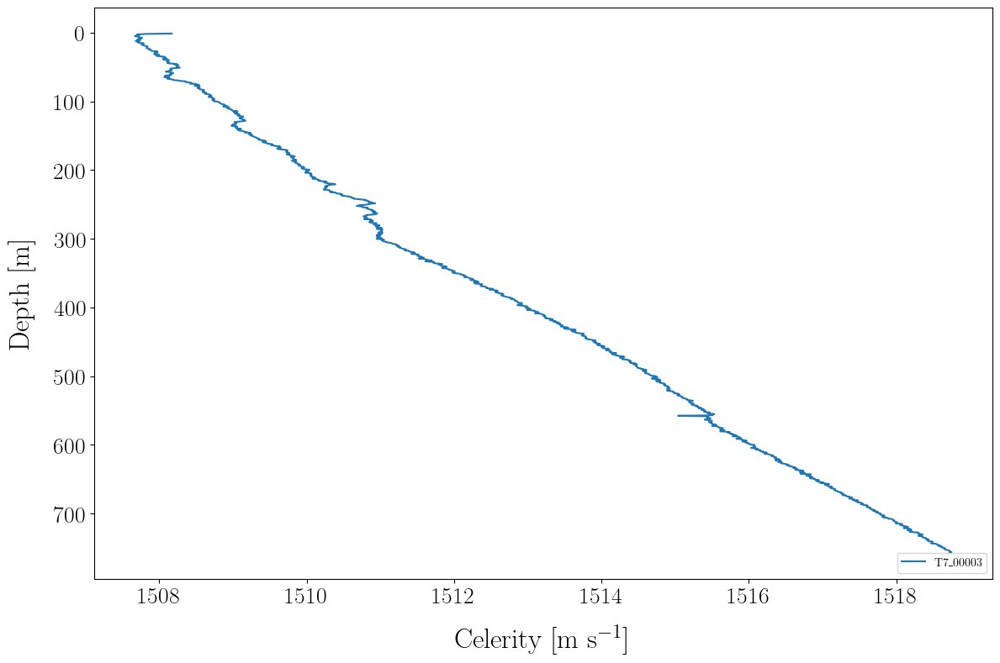

In [10]:
selected_profile = "T7_00003"
# selected_profile = "T0_00020"

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
for name, node in celerity.children.items():
    if name == selected_profile:
        ds = node.to_dataset()
        ds.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)

    # ds = node.to_dataset()
    # ds.celerity.plot(y="depth", ax=ax, yincrease=False, label=name)


# for ax in axs.flatten():
ax.legend(loc="lower right", ncols=2, fontsize=10)
# axs[1].legend(loc="upper right", ncols=2, fontsize=10)
# axs[1].set_ylabel("")

# plt.ylim(500, 0)

In [11]:
ds_ = ds.sel(depth=slice(0, 100))
c_eq = equivalent_celerity(ds_.celerity.values, ds_.celerity.depth.values)
c_eq

np.float64(1508.1731018573482)

### Calcul des temps de propagation associés à chaque couple émission / récepteur 

In [12]:
c0 = c_eq
for name, node in portion.position.children.items():
    ds_pos_section = node.to_dataset()
    # Propagation distance assuming strait line propagation path
    dpropa_direct = np.sqrt(ds_pos_section.src_rcv_geodesic_dist**2 + ds_pos_section.rcv_immersion**2)
    # Compute propagation time 
    tps_propagation_s = dpropa_direct / c0 
    # tps_propagation_s = ds_pos_section.src_rcv_geodesic_dist / c0 
    ds_pos_section["tps_propagation_s"] = tps_propagation_s

    # Derive associated arrival dt 
    tps_propagation_ns = (tps_propagation_s * 1e9).round()
    tps_propagation_td = tps_propagation_ns.astype("timedelta64[ns]")
    ds_pos_section["tir_reception_datetime"] = tps_propagation_td + ds_pos_section.src_datetime

    # Update tree
    node.ds = ds_pos_section

In [13]:
ds_pos_section.tps_propagation_s

<xarray.DataArray 'tps_propagation_s' (rcv_id: 7, src_datetime: 200)> Size: 11kB
array([[2.07333125, 2.07248621, 2.07165302, ..., 2.14902493, 2.15069233,
        2.1523876 ],
       [1.99018291, 1.98923879, 1.98830693, ..., 2.05644685, 2.05812054,
        2.05982263],
       [2.07196787, 2.0733538 , 2.07475099, ..., 2.53812063, 2.5413686 ,
        2.5446566 ],
       ...,
       [9.22487567, 9.22173768, 9.21860136, ..., 8.64464875, 8.64197423,
        8.6392728 ],
       [1.43926073, 1.43559465, 1.43193681, ..., 0.97767165, 0.97724123,
        0.97683364],
       [1.5583739 , 1.55434158, 1.55031505, ..., 0.95683263, 0.95533801,
        0.95385333]], shape=(7, 200))
Coordinates:
  * rcv_id        (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' ... 'obs6' 'obs7' 'tlq'
  * src_datetime  (src_datetime) datetime64[ns] 2kB 2026-02-25T05:15:00.60009...
Attributes:
    units:      m
    long_name:  Immersion below MSL

In [14]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                    ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:5...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 968B 2026-02-25T09:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 3kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 9kB ...
│   │           atl_lat                 (atl_datetime) float64 9kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 509kB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 3kB 43.05 43.05 ... 43.02
│   │           tir_vessel_lon          (src_datetime) float64 3kB ...
│   │           tir_vessel_lat          (src_datetime) float64 3kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 22kB 4.11e+03 ... ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 22kB 2.726 ... 2.458
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 22kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                    ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:4...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T00:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 2kB 2026-02-25T00:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 5kB ...
│   │           atl_lat                 (atl_datetime) float64 5kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 257kB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 2kB 43.03 43.03 ... 43.03
│   │           tir_vessel_lon          (src_datetime) float64 2kB ...
│   │           tir_vessel_lat          (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 11kB 1.849e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 11kB 1.229 ... 1.773
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 11kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:

In [15]:
(portion.position.sn1.rcv_immersion, portion.position.sn1.rcv_id)

(<xarray.DataArray 'rcv_immersion' (rcv_id: 7)> Size: 14B
 array([ 119,  116,  118, 1077,  306,   93,   93], dtype=int16)
 Coordinates:
   * rcv_id   (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7' 'tlq'
 Attributes:
     units:      m
     long_name:  Immersion below MSL,
 <xarray.DataArray 'rcv_id' (rcv_id: 7)> Size: 112B
 array(['obs1', 'obs2', 'obs4', 'obs5', 'obs6', 'obs7', 'tlq'], dtype='<U4')
 Coordinates:
   * rcv_id   (rcv_id) <U4 112B 'obs1' 'obs2' 'obs4' 'obs5' 'obs6' 'obs7' 'tlq')

### Comparaison aux signaux 

In [16]:
# r = ds_pos_section.src_rcv_geodesic_dist.max()
# delta_c = 10
# delta_t = (r*delta_c) / c0**2
# delta_t

c0 = 1508
delta_r = 200
delta_t = 1 / c0 * delta_r
delta_t


0.1326259946949602

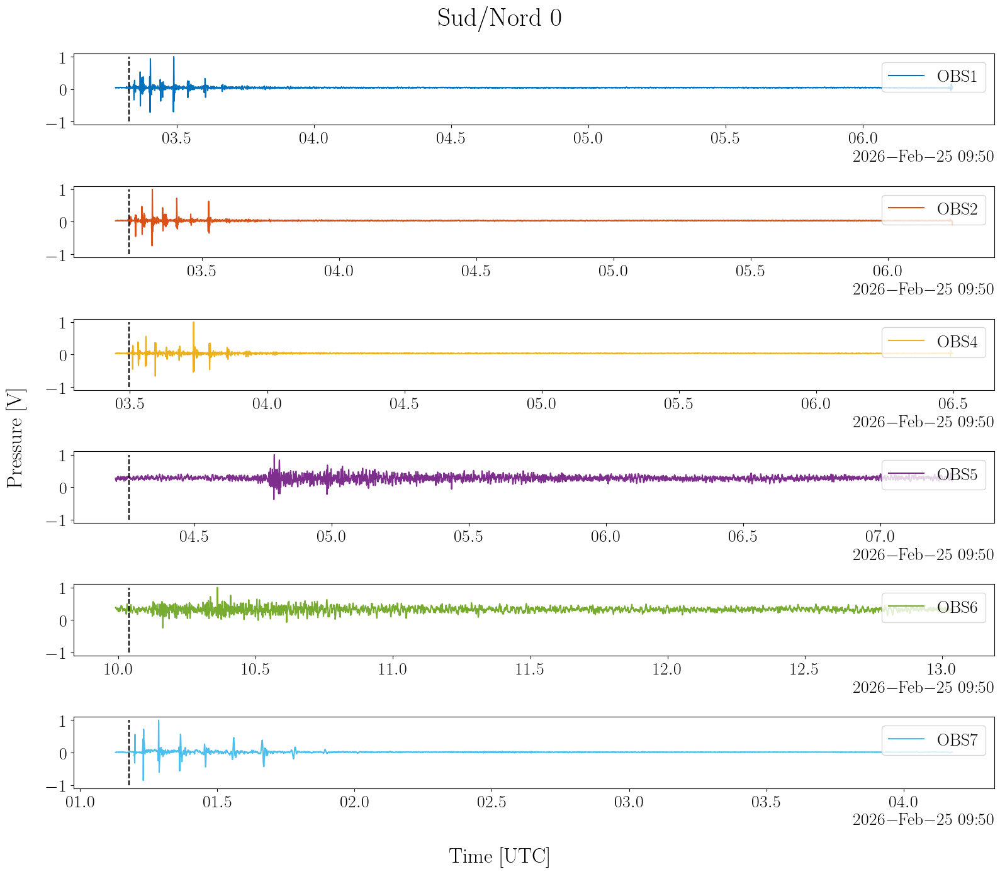

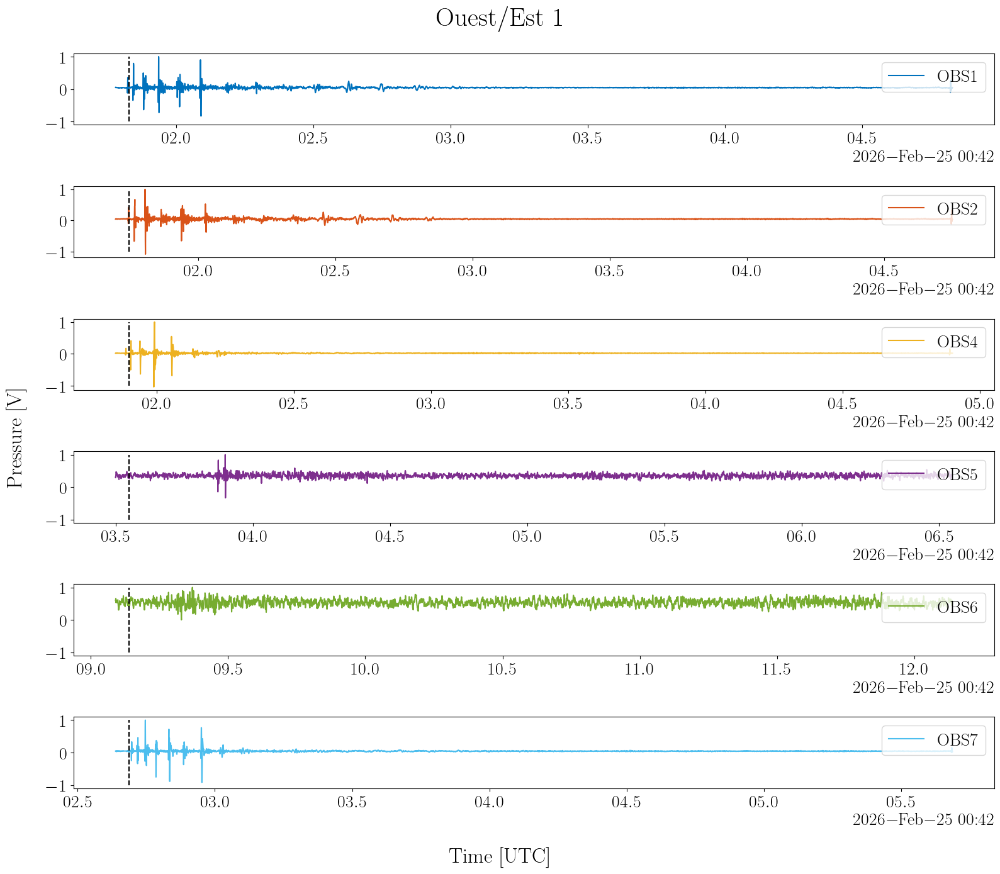

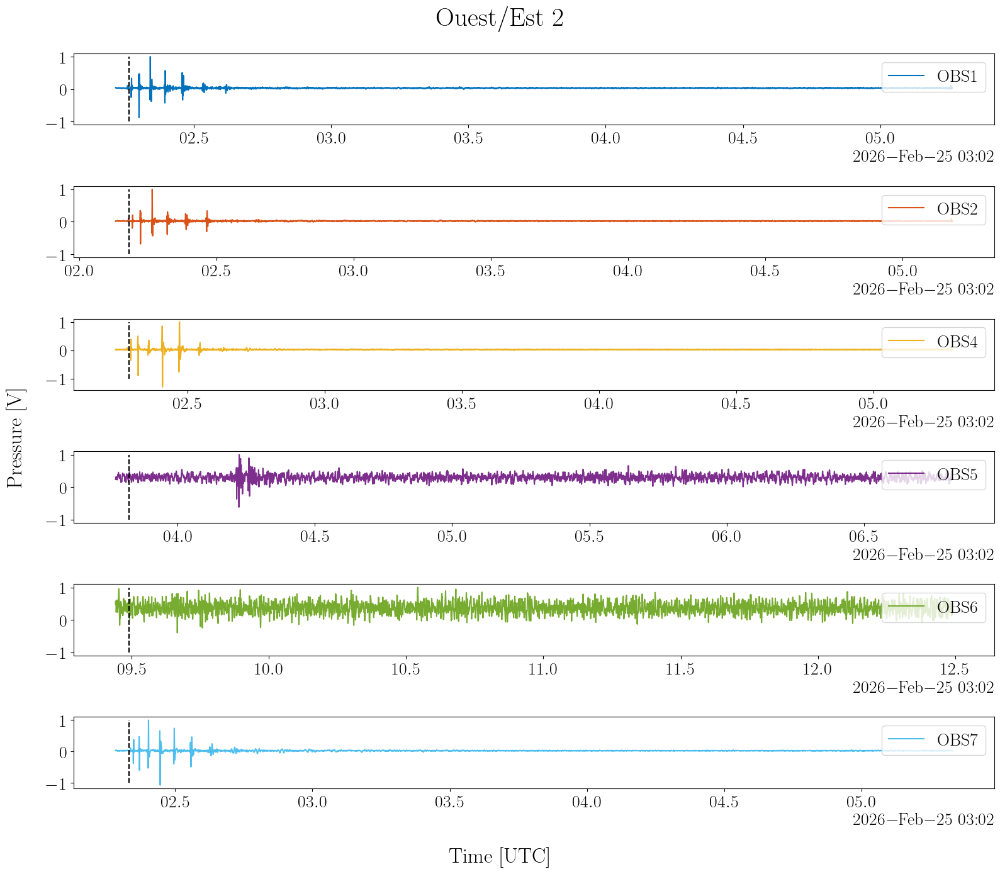

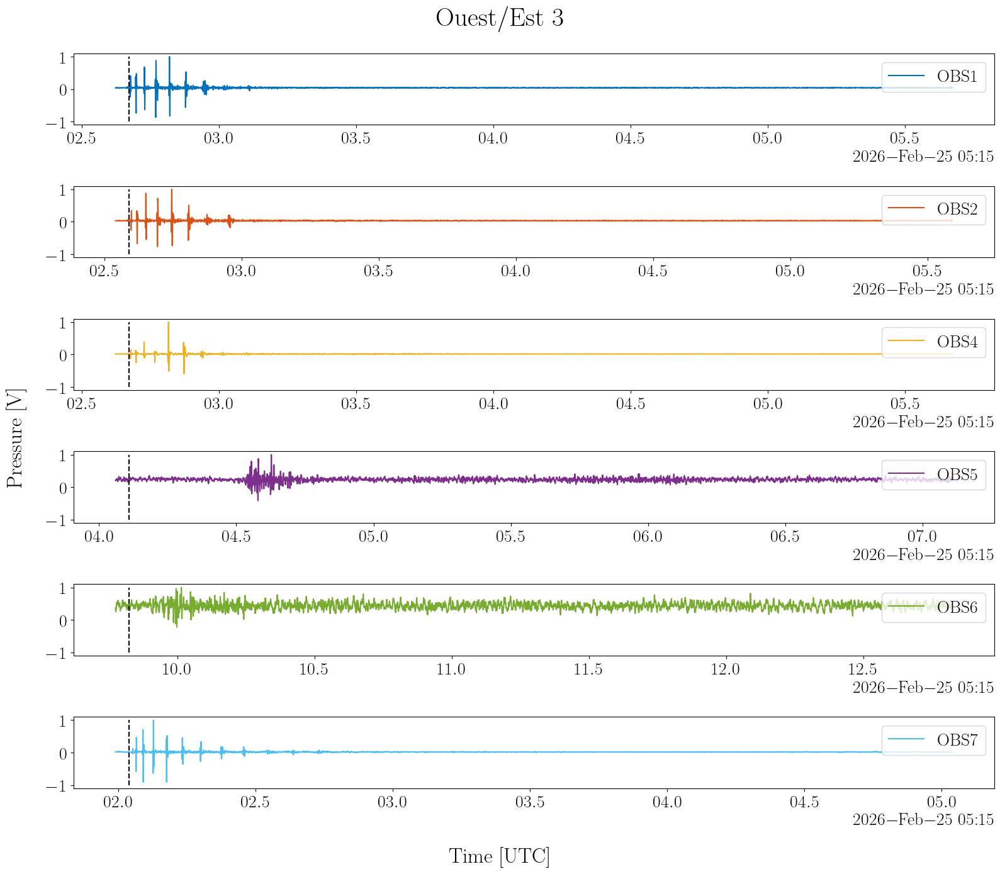

In [17]:
nb_tir = 1
offset1 = 50
offset2 = 3000

obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values
# obs_ids = obs_ids[[0, 3, 5]]
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()
    tir_dt = ds_pos_section["tir_reception_datetime"].isel(src_datetime=slice(0, 0+nb_tir))

    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=1, figsize=(16, 14), sharex=False)        
    axs = axs.flatten()
    for i, rcv_id in enumerate(obs_ids):
        tir_dt_rcv = tir_dt.sel(rcv_id=rcv_id)
        # Select associated data window 
        press_rcv = ds_pressure_section[f"pressure_{rcv_id}"].sel({f"time_{rcv_id}":slice(tir_dt_rcv.values[0]-np.timedelta64(offset1, 'ms'), tir_dt_rcv.values[-1]+np.timedelta64(offset2, 'ms'))})
        # Plot pressure signal 
        # Normalize 
        press_rcv = press_rcv / press_rcv.max()
        press_rcv.plot(label=rcv_id.upper(), color=color(i), ax=axs[i])
        # Plot arrivals time 
        axs[i].vlines(x=tir_dt_rcv, ymin=-1, ymax=1, color="k", linestyle="--")
        # Add legend
        axs[i].legend(loc="upper right")

    xlab = axs[0].get_xlabel()
    ylab = axs[0].get_ylabel()

    for ax in axs:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title("")

    fig.suptitle(f"{ds_pressure_section.section_orientation} {ds_pressure_section.section_id}")
    fig.supxlabel(xlab)
    fig.supylabel(ylab)

    plt.show()

# Calcul des grandeurs signantes 

In [65]:
nb_tir = 1
offset_ms = 100
signal_duration_s = 3
signal_duration_ms = int(signal_duration_s * 1000)
nfft = 2**15


obs_ids = list(portion.pressure.children.items())[0][1].to_dataset().obs_id.values

# 1) Iterate over portion's sections
for name, node in portion.pressure.children.items():
    ds_pressure_section = node.to_dataset()  
    # Associated ds_pos
    ds_pos_section = portion.position[name].to_dataset()

    Sxy_data = []
    valid_emission_dt = []
    # 2) Iterate over emissions
    for i_tir, tir_emission_dt in enumerate(ds_pos_section.src_datetime.values):
        ds_pos_section_current_tir = ds_pos_section.sel(src_datetime=tir_emission_dt)

        # Reception datetime
        tir_reception_dt = ds_pos_section_current_tir["tir_reception_datetime"]

        # 3) Build list of signal_i
        signal_arr = []
        for i in range(obs_ids.size):
            rcv_id_i = obs_ids[i]
            # Reception datetime for current rcv i
            tir_reception_dt_rcvi = tir_reception_dt.sel(rcv_id=rcv_id_i)

            # Select associated data window
            signal_i = ds_pressure_section[f"pressure_{rcv_id_i}"].sel({f"time_{rcv_id_i}":slice(tir_reception_dt_rcvi.data-np.timedelta64(offset_ms, 'ms'), tir_reception_dt_rcvi.data+np.timedelta64(signal_duration_ms-offset_ms, 'ms'))})

            # Ensure signal is centered
            signal_i = signal_i - np.nanmean(signal_i)

            # Store in array
            signal_arr.append(signal_i.values)

        # Check all rcv have complete signal
        signal_is_complete = np.all(
            [signal_arr[k].size == int(signal_duration_s * ds_pressure_section.fs) for k in range(len(signal_arr))]
        )
        # print(signal_is_complete)
        if signal_is_complete:
            valid_emission_dt.append(tir_emission_dt)
            signal_arr = np.asarray(signal_arr)     # (nrcv, nt)
        else:
            continue

        # a) Compute PSD Sxx
        rfft = np.fft.rfft(signal_arr, n=nfft, axis=1)      # (nrcv, nfft)
        Sxx_arr = rfft * np.conj(rfft)  # (nrcv, nfft)

        # a) Compute CPSD Sxy
        # Ugly double loop to vectorized
        nr, nf = rfft.shape
        Sxy_arr = np.empty(shape=(nr, nr, nf), dtype=np.complex64) * np.nan
        for i in range(obs_ids.size):
            Sxy_arr[i, i, :] = Sxx_arr[i, :]        # Diagonal = PSD 
            x_fft_i = rfft[i, :]
            for j in range(i, obs_ids.size):
                rcv_id_j = obs_ids[j]
                y_fft_j = rfft[j, :]
                Sxy = x_fft_i * np.conj(y_fft_j)
                # Upper triangle Sij
                Sxy_arr[i, j] = Sxy
                # Lower triangle Sji = conj(Sij)
                Sxy_arr[j, i] = np.conj(Sxy)

        # Store for current tir
        Sxy_data.append(Sxy_arr)
    Sxy_data = np.array(Sxy_data)   # (ntir, nr, nr, nf)

    # Store in ds_pressure_section
    ds_feature = ds_pos_section.copy()
    ds_feature = ds_feature.drop_vars(
        [
            "atl_lon",
            "atl_lat",
            "atl_datetime",
            "ais_lon",
            "ais_lat",
            "ais_datetime",
            "tir_SEGD",
            "tir_ECOS",
            "tir_vessel_lon",
            "tir_vessel_lat",
        ]
    ) 
    attrs = ds_feature.attrs
    attrs.pop("interpolation_time_step")
    attrs["description"] = "Localisation features"

    # Sel only valid tir
    ds_feature = ds_feature.sel(src_datetime=valid_emission_dt)

    # Add coords rcv_i, rcv_j and freq
    freq = np.fft.rfftfreq(nfft, d=1 / ds_pressure_section.fs)

    ds_feature = ds_feature.assign_coords(
        dict(rcv_i=obs_ids, rcv_j=obs_ids, freq=freq)
    )  # NOTE we need to declare new coords because we can use duplicated coords

    ds_feature["Sxy"] = (["src_datetime", "rcv_i", "rcv_j", "freq"], Sxy_data)

    # Update tree
    portion[f"/feature/{name}"] = ds_feature


C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_7732\1266567884.py:36: RuntimeWarning: Mean of empty slice
  signal_i = signal_i - np.nanmean(signal_i)


In [66]:
portion

<xarray.DataTree>
Group: /
├── Group: /position
│   ├── Group: /position/sn1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 1144, mmsi: 526,
│   │                                    ais_datetime: 121, src_datetime: 390)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 9kB 2026-02-25T09:5...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 968B 2026-02-25T09:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 3kB 2026-02-25T09:5...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 9kB 5.957 5.957 ... 5.957
│   │           atl_lat                 (atl_datetime) float64 9kB 43.05 43.05 ... 43.02
│   │           ais_lon                 (mmsi, ais_datetime) float64 509kB nan nan ... nan
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 3kB 43.05 43.05 ... 43.02
│   │           tir_vessel_lon          (src_datetime) float64 3kB 5.957 5.957 ... 5.957
│   │           tir_vessel_lat          (src_datetime) float64 3kB 43.05 43.05 ... 43.02
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 22kB 4.11e+03 ... ...
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 22kB 2.726 ... 2.458
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 22kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS interpolées
│   │           interpolation_time_step:  10s
│   │           campagne:                 ACOUPLANE
│   │           geodesic_frame:           WGS84
│   │           portion_id:               1
│   │           section_orientation:      Sud/Nord
│   │           section_id:               0
│   ├── Group: /position/oe1
│   │       Dimensions:                 (rcv_id: 7, atl_datetime: 600, mmsi: 526,
│   │                                    ais_datetime: 61, src_datetime: 200)
│   │       Coordinates:
│   │         * rcv_id                  (rcv_id) <U4 112B 'obs1' 'obs2' ... 'obs7' 'tlq'
│   │         * atl_datetime            (atl_datetime) datetime64[ns] 5kB 2026-02-25T00:4...
│   │         * ais_datetime            (ais_datetime) datetime64[ns] 488B 2026-02-25T00:...
│   │         * src_datetime            (src_datetime) datetime64[ns] 2kB 2026-02-25T00:4...
│   │       Dimensions without coordinates: mmsi
│   │       Data variables: (12/16)
│   │           rcv_lon                 (rcv_id) float64 56B 5.952 5.953 ... 5.966 5.97
│   │           rcv_lat                 (rcv_id) float64 56B 43.02 43.02 ... 43.06 43.06
│   │           rcv_immersion           (rcv_id) int16 14B 119 116 118 1077 306 93 93
│   │           atl_lon                 (atl_datetime) float64 5kB ...
│   │           atl_lat                 (atl_datetime) float64 5kB ...
│   │           ais_lon                 (mmsi, ais_datetime) float64 257kB ...
│   │           ...                      ...
│   │           tir_src_lat             (src_datetime) float64 2kB 43.03 43.03 ... 43.03
│   │           tir_vessel_lon          (src_datetime) float64 2kB ...
│   │           tir_vessel_lat          (src_datetime) float64 2kB ...
│   │           src_rcv_geodesic_dist   (rcv_id, src_datetime) float64 11kB 1.849e+03 ......
│   │           tps_propagation_s       (rcv_id, src_datetime) float64 11kB 1.229 ... 1.773
│   │           tir_reception_datetime  (rcv_id, src_datetime) datetime64[ns] 11kB 2026-0...
│   │       Attributes:
│   │           description:              Positions AIS

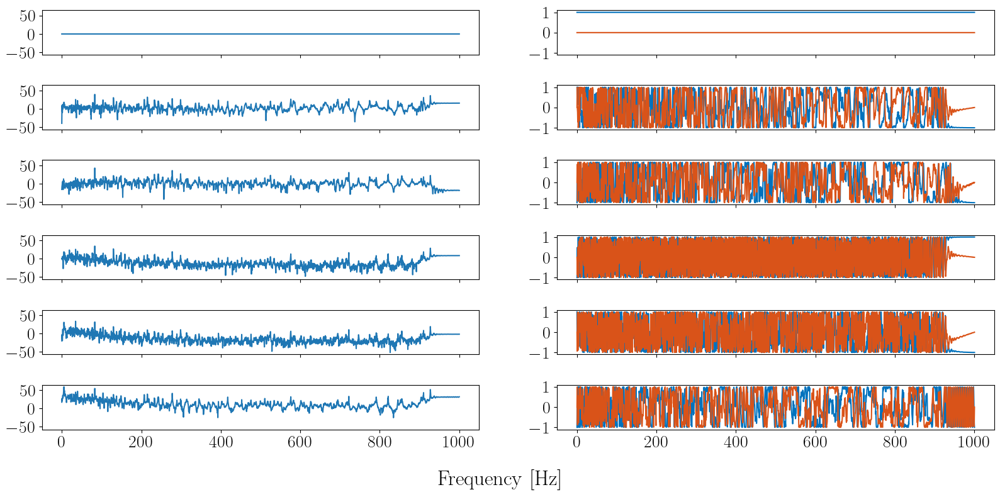

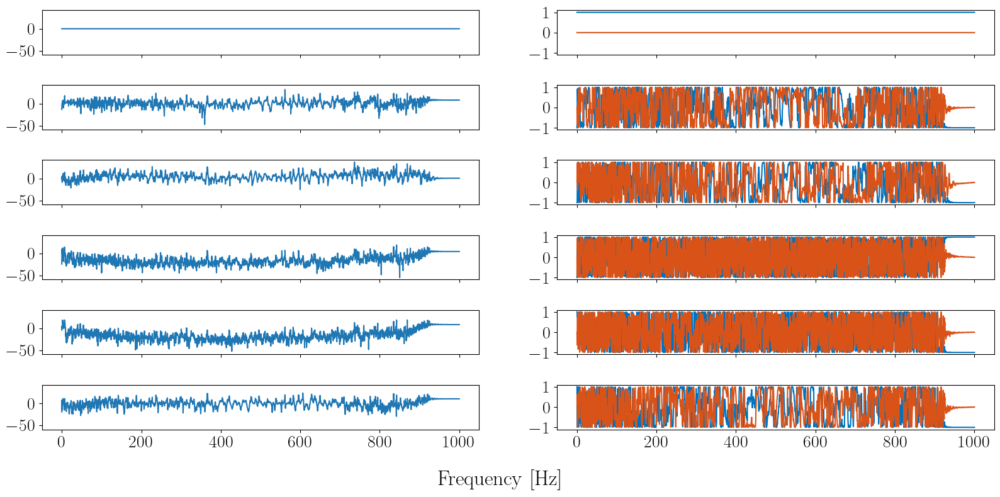

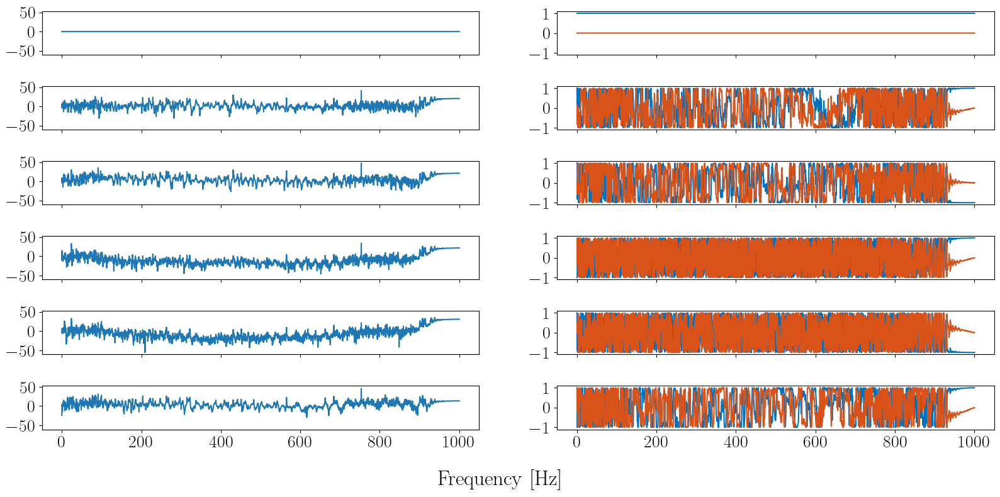

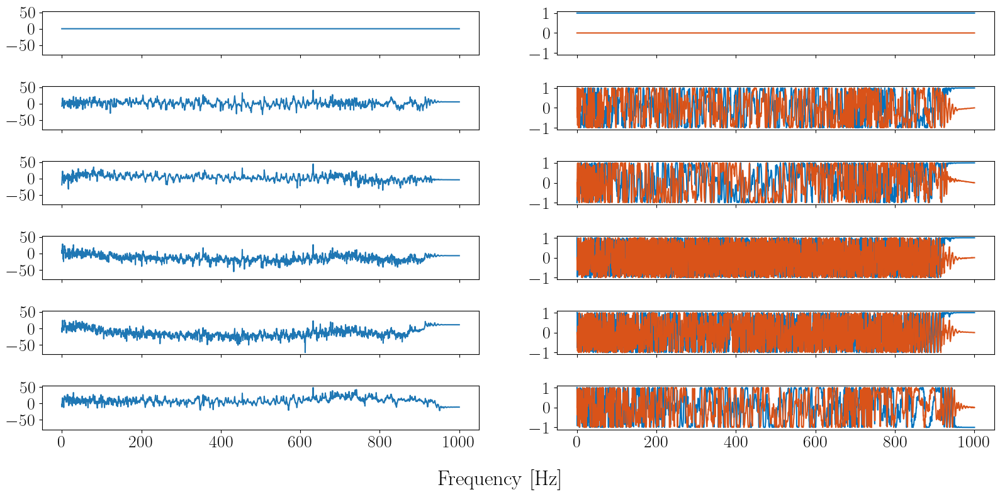

In [37]:
ref_rcv_id = "obs1"

# print(axs.shape)
for name, node in portion.feature.children.items():
    ds_feature_section = node.to_dataset()

    ds_feature_section = ds_feature_section.isel(src_datetime=0)

    sjj = ds_feature_section.sel(rcv_i=ref_rcv_id, rcv_j=ref_rcv_id).Sxy
    # Per convention : 2nd index = ref
    fig, axs = plt.subplots(nrows=obs_ids.size, ncols=2, figsize=(16, 8), sharex=True, sharey="col")

    for i_rcv, rcv_id_i in enumerate(obs_ids):

        # Sii
        sii = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=rcv_id_i).Sxy
        # Sij
        sij = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=ref_rcv_id).Sxy

        # RTF
        pi_ij = sij / sjj
        gamma_ij = 20 * np.log10(np.abs(pi_ij))
        # np.abs(pi_ij).plot(ax=axs[i_rcv, 0])
        gamma_ij.plot(ax=axs[i_rcv, 0])
        
        # DCF (sxy SCOT)
        dcf_ij = sij / np.sqrt(sii * sjj)
        np.real(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(0))
        np.imag(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(1))

    for ax in axs.flatten():
        ax.set_title("")
        ax.set_xlabel("")
        ax.set_ylabel("")

    fig.supxlabel("Frequency [Hz]")

c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\xarray\computation\apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\xarray\computation\apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\xarray\computation\apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)


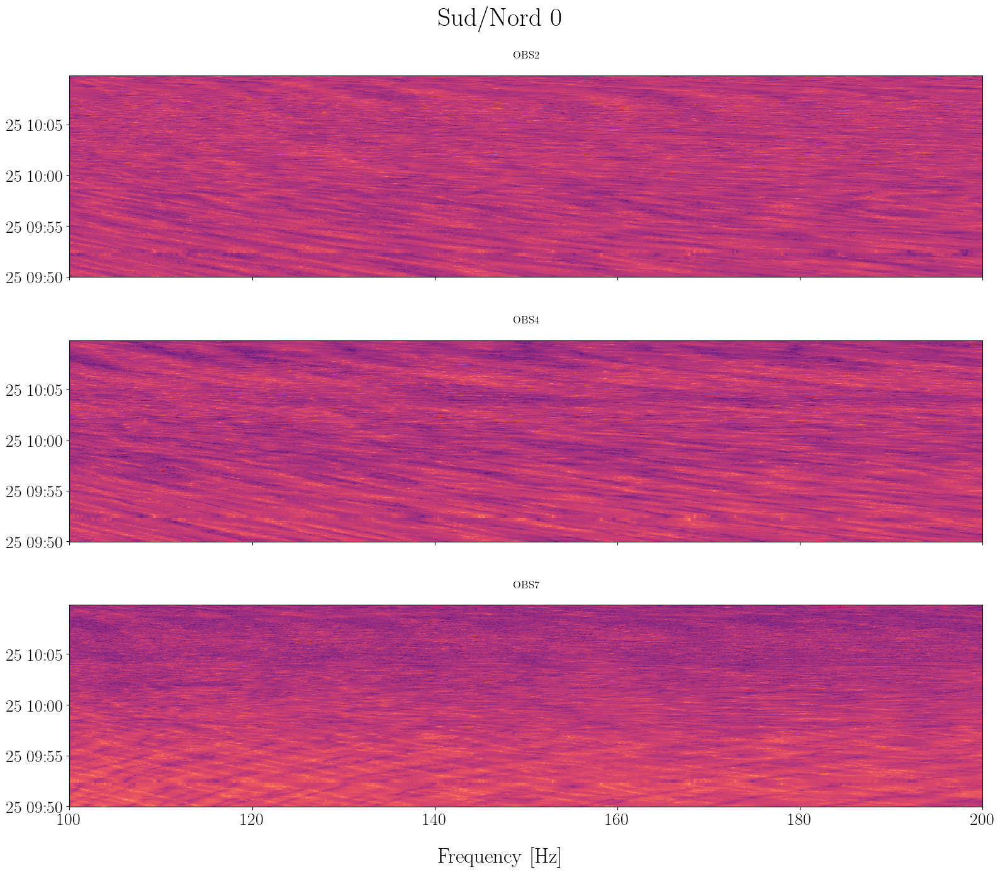

c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\xarray\computation\apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)


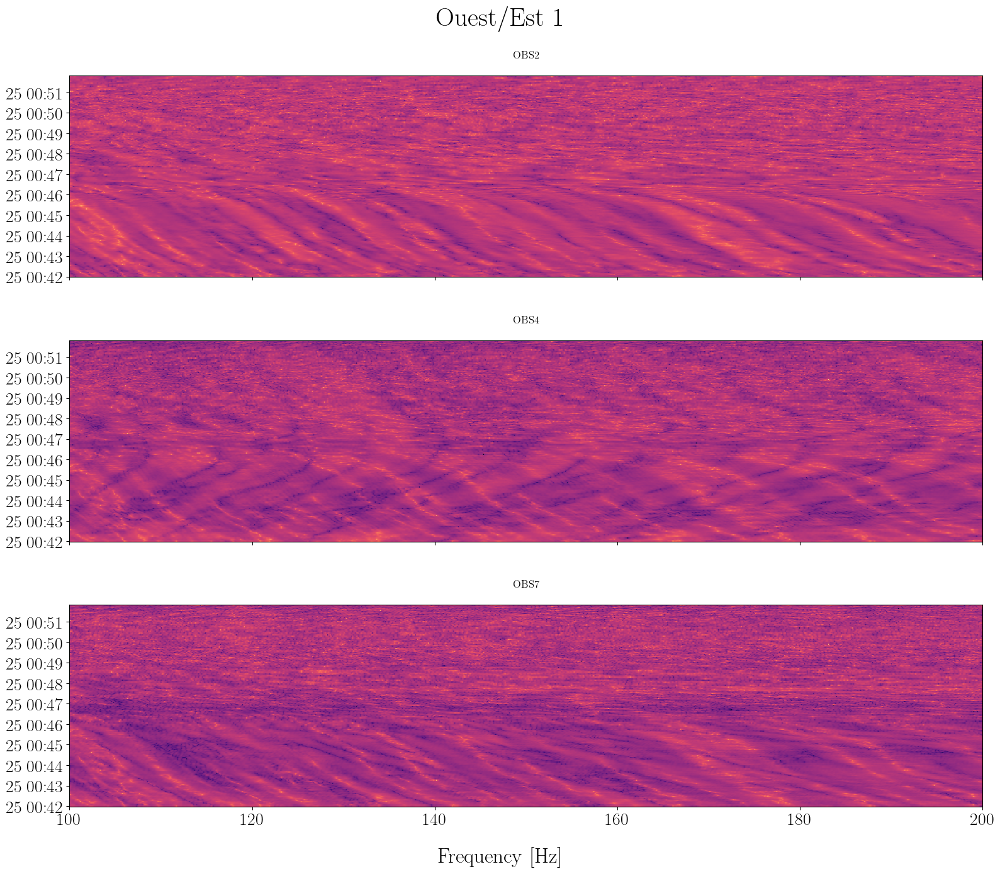

c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\xarray\computation\apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)


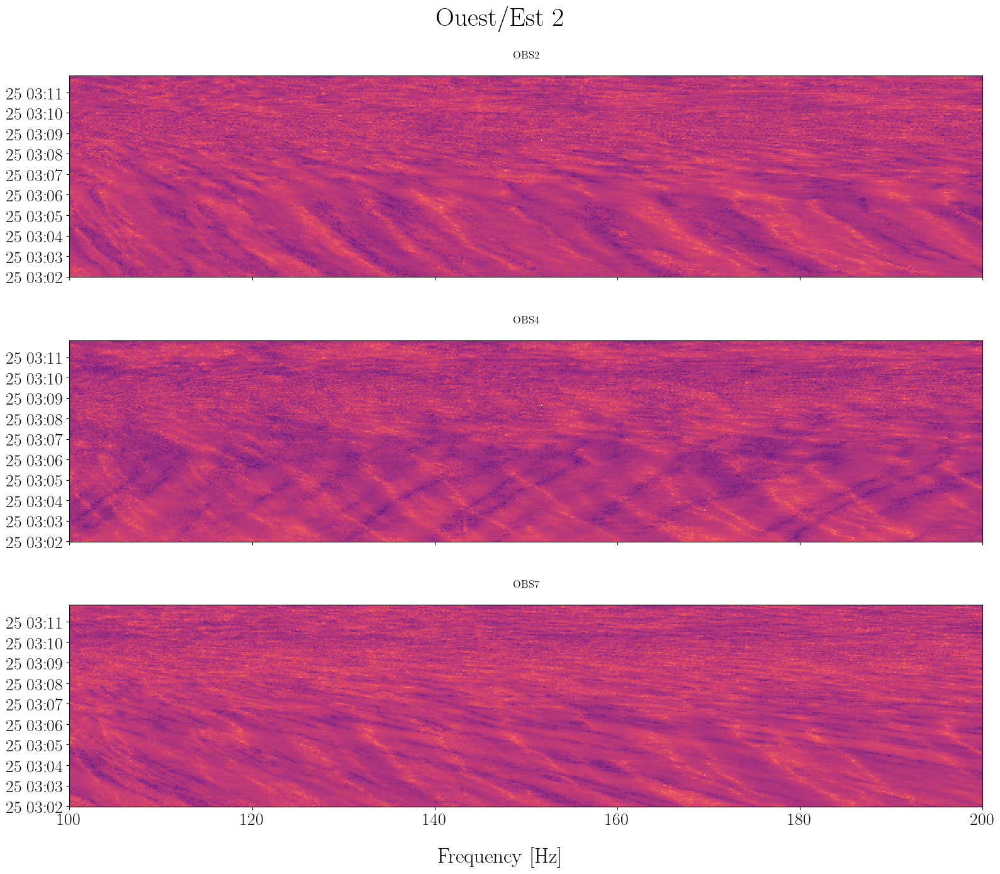

c:\Users\baptiste.menetrier\.virtualenvs\phd-FBjz4hBd\Lib\site-packages\xarray\computation\apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)


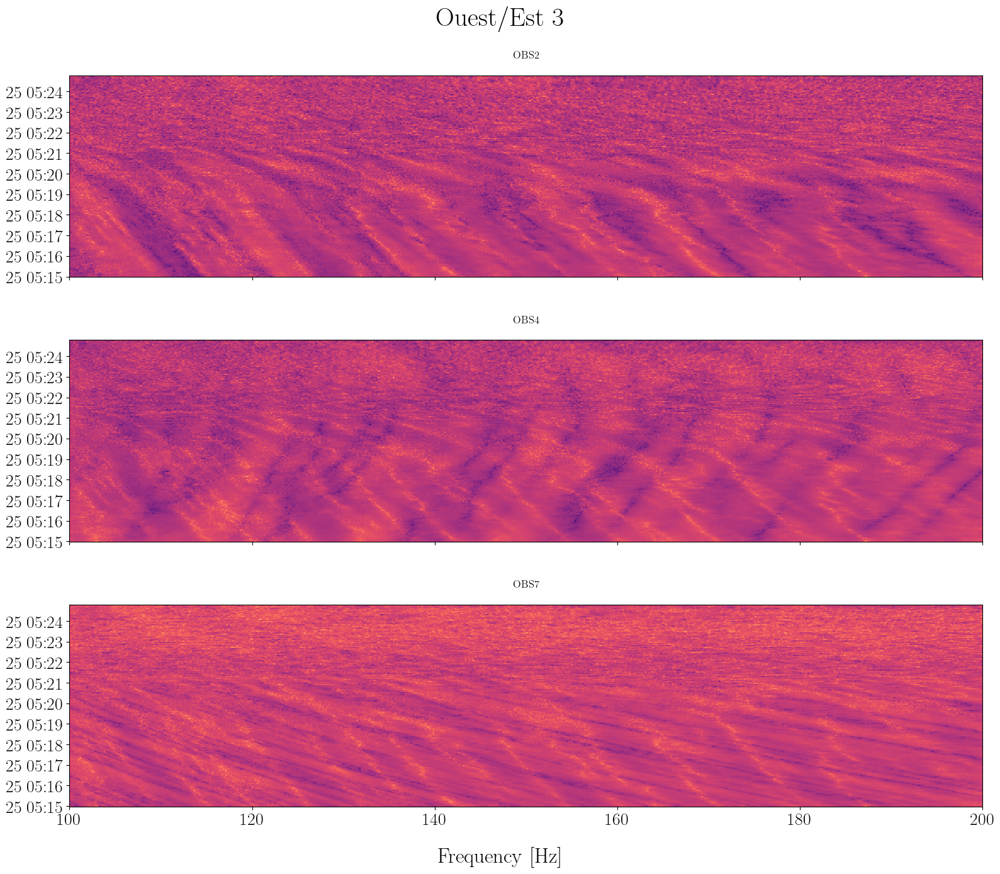

In [70]:
ref_rcv_id = "obs1"
obs_ids_visu = obs_ids[[0, 1, 2, -1]]

# print(axs.shape)
for name, node in portion.feature.children.items():
    ds_feature_section = node.to_dataset()

    sjj = ds_feature_section.sel(rcv_i=ref_rcv_id, rcv_j=ref_rcv_id).Sxy
    # Per convention : 2nd index = ref

    fig, axs = plt.subplots(
        nrows=obs_ids_visu.size-1, ncols=1, figsize=(16, 14), sharex=True, sharey=True
    )
    axs = axs.flatten()
    iplot = 0
    for i_rcv, rcv_id_i in enumerate(obs_ids_visu):

        if rcv_id_i == ref_rcv_id:
            continue
        # Sii
        sii = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=rcv_id_i).Sxy
        # Sij
        sij = ds_feature_section.sel(rcv_i=rcv_id_i, rcv_j=ref_rcv_id).Sxy

        # RTF
        pi_ij = sij / sjj
        gamma_ij = 20 * np.log10(np.abs(pi_ij))
        # np.abs(pi_ij).plot(ax=axs[i_rcv, 0])
        gamma_ij.plot(x="freq", ax=axs[iplot], cmap="magma", add_colorbar=False)

        axs[iplot].set_xlabel("")
        axs[iplot].set_ylabel("")
        # axs[iplot].set_title("")
        axs[iplot].set_title(rcv_id_i.upper(), fontsize=12)
        iplot += 1

    fig.supxlabel("Frequency [Hz]")
    fig.suptitle(
        f"{ds_feature_section.section_orientation} {ds_feature_section.section_id}"
    )
    plt.xlim(100, 200)
    plt.show()

    # # DCF (sxy SCOT)
    # dcf_ij = sij / np.sqrt(sii * sjj)
    # np.real(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(0))
    # np.imag(dcf_ij).plot(ax=axs[i_rcv, 1], color=color(1))

    # for ax in axs.flatten():
    #     ax.set_title("")
    #     ax.set_xlabel("")
    #     ax.set_ylabel("")

    # fig.supxlabel("Frequency [Hz]")

# Etude des intersections 

(<Figure size 1600x800 with 1 Axes>,
 <Axes: title={'center': 'OBS positions'}, xlabel='Longitude [°]', ylabel='Latitude [°]'>)

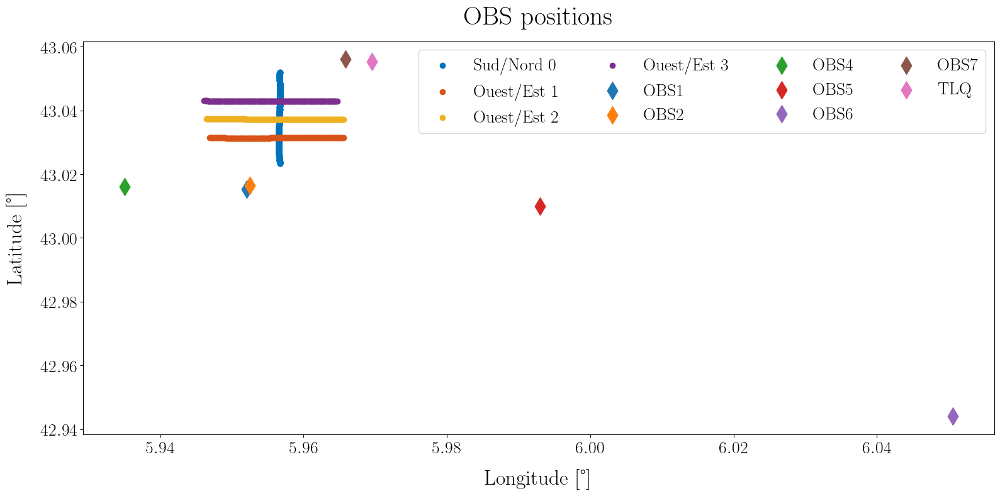

In [71]:
plot_portion_tir_pos(portion_tree=portion)

## Sud/Nord 0 - Ouest/Est 1

In [194]:
section_1_name = "sn1"
section_2_name = "oe1"
ds_feature_section1 = portion.feature[section_1_name].to_dataset()
ds_feature_section2 = portion.feature[section_2_name].to_dataset()

### CPA 

In [195]:
from pyproj import Geod

geod = Geod(ellps="WGS84")

src_lon1, src_lat1 = (
    ds_feature_section1.tir_src_lon,
    ds_feature_section1.tir_src_lat,
)
src_lon2, srcv_lat2 = (
    ds_feature_section2.tir_src_lon,
    ds_feature_section2.tir_src_lat,
)

dist_12 = []
for i in range(src_lon2.sizes["src_datetime"]):

    # Cast to src pos shape
    lon2 = np.ones(src_lon1.size) * src_lon2.isel(src_datetime=i).values
    lat2 = np.ones(src_lon1.size) * srcv_lat2.isel(src_datetime=i).values

    # Compute geodesic distance
    fwd_az, back_az, horiz_d = geod.inv(
        lons1=src_lon1.values, lats1=src_lat1.values, lons2=lon2, lats2=lat2
    )

    dist_12.append(horiz_d)

dist_12 = np.asarray(dist_12)

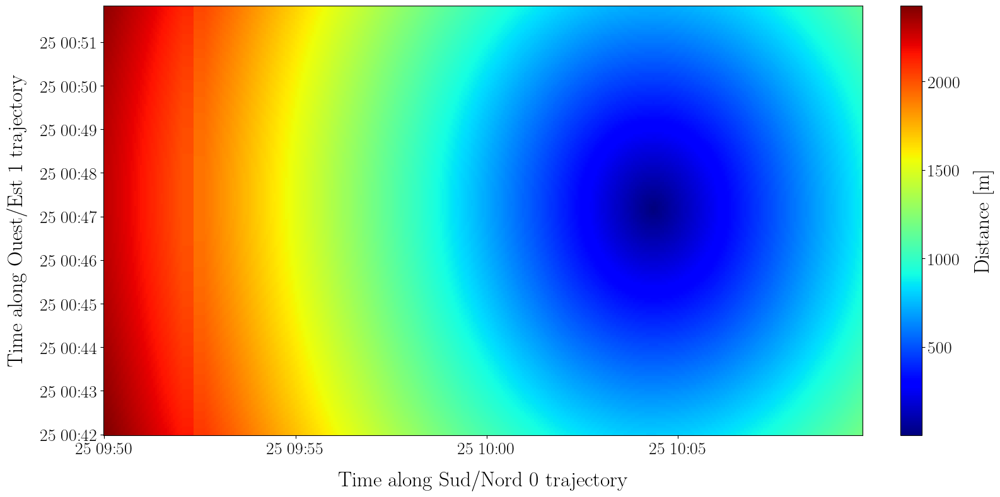

In [196]:
im = plt.pcolormesh(src_lon1.src_datetime, src_lon2.src_datetime, dist_12, cmap="jet")
plt.xlabel(f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory")
plt.ylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)
plt.colorbar(im, label="Distance [m]")

### Distance dans l'espace des données 

In [212]:
rcv_id_i = "obs2"
ref_rcv_id = "obs1"

fmin = 5
fmax = 50

### Section 1 ###
sjj = ds_feature_section1.sel(
    rcv_i=ref_rcv_id, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
).Sxy
# Sij
sij = ds_feature_section1.sel(
    rcv_i=rcv_id_i, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
).Sxy
# RTF
pi_ij_a = sij.values / sjj.values
pi_a = pi_ij_a[:, np.newaxis, :]  # (nt1, 1, nf)
gamma_a = 20 * np.log10(np.abs(pi_ij_a))  # (nt1, nf)
gamma_a = gamma_a[:, np.newaxis, :]     # (nt1, 1, nf)

### Section 2 ###
sjj = ds_feature_section2.sel(
    rcv_i=ref_rcv_id, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
).Sxy
# Sij
sij = ds_feature_section2.sel(
    rcv_i=rcv_id_i, rcv_j=ref_rcv_id, freq=slice(fmin, fmax)
).Sxy
# RTF
pi_ij_b = sij.values / sjj.values
pi_b = pi_ij_b[np.newaxis, :, :]  # (1, nt2, nf)
gamma_b = 20 * np.log10(np.abs(pi_ij_b))  # (nt2, nf)
gamma_b = gamma_b[np.newaxis, :, :]     # (1, nt2, nf)

# Compute theta with pi
inner_prod = np.nansum(pi_a * np.conj(pi_b), axis=-1)
norm_a = np.sqrt(np.nansum(pi_a * np.conj(pi_a), axis=-1))
norm_b = np.sqrt(np.nansum(pi_b * np.conj(pi_b), axis=-1))
# Clip to [0, 1] for stability
cos_angle = np.clip(np.abs(inner_prod) / np.abs(norm_a * norm_b), 0, 1.0)
dist_theta = 1 - cos_angle  #  to [0, 1]

# Compute L2 with gamma
dist_L2_gamma = np.sqrt(np.nansum(np.abs(gamma_a - gamma_b) ** 2, axis=-1))
dist_L2_gamma = dist_L2_gamma / np.nanmax(dist_L2_gamma)  # Normalize to [0, 1]

# Compute theta with gamma
inner_prod = np.nansum(gamma_a * gamma_b, axis=-1)
norm_a = np.sqrt(np.nansum(gamma_a**2, axis=-1))
norm_b = np.sqrt(np.nansum(gamma_b**2, axis=-1))
# Clip to [-1, 1] for stability
cos_angle = np.clip(inner_prod / (norm_a * norm_b), -1.0, 1.0)
dist_theta_gamma = (1 - cos_angle) / 2  #  [-1, 1] to [0, 1]

In [213]:
ind_min_dist = np.argmin(dist_12)
xx, yy = np.meshgrid(src_lon1.src_datetime, src_lon2.src_datetime)
xmin, ymin = xx.flatten()[ind_min_dist], yy.flatten()[ind_min_dist]

# Theta with pi
ind_min_theta = np.argmin(dist_theta.T)
xmin_theta, ymin_theta = xx.flatten()[ind_min_theta], yy.flatten()[ind_min_theta]

# Theta with gamma
ind_min_theta_gamma = np.argmin(dist_theta_gamma.T)
xmin_theta_gamma, ymin_theta_gamma = (
    xx.flatten()[ind_min_theta_gamma],
    yy.flatten()[ind_min_theta_gamma],
)

# L2 with gamma
ind_min_L2_gamma = np.argmin(dist_L2_gamma.T)
xmin_L2_gamma, ymin_L2_gamma = (
    xx.flatten()[ind_min_L2_gamma],
    yy.flatten()[ind_min_L2_gamma],
)

#### R vs theta 

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

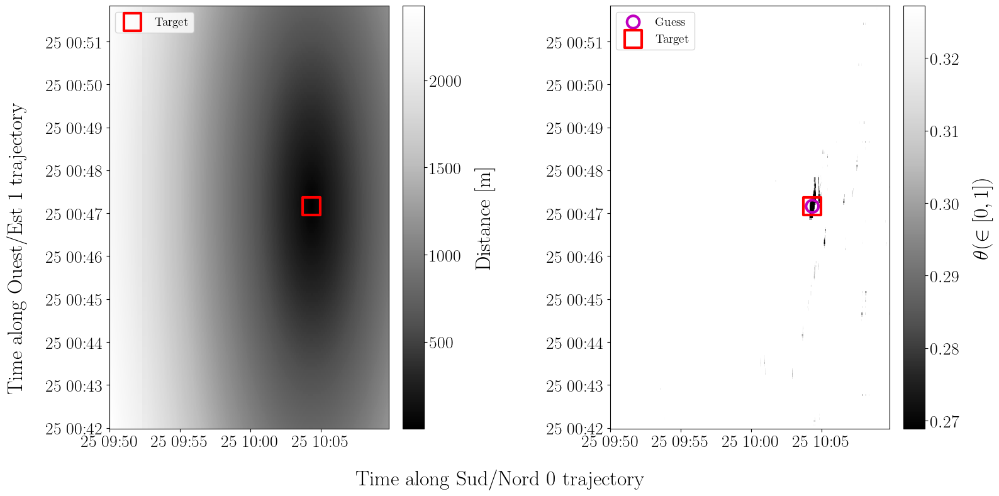

In [208]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))
im = axs[0].pcolormesh(src_lon1.src_datetime, src_lon2.src_datetime, dist_12, cmap="Grays_r")
plt.colorbar(im, ax=axs[0], label="Distance [m]")
im = axs[1].pcolormesh(
    src_lon1.src_datetime,
    src_lon2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$\theta (\in [0, 1])$")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### $\theta_{\gamma}$ vs $\theta_{\Pi}$ 

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

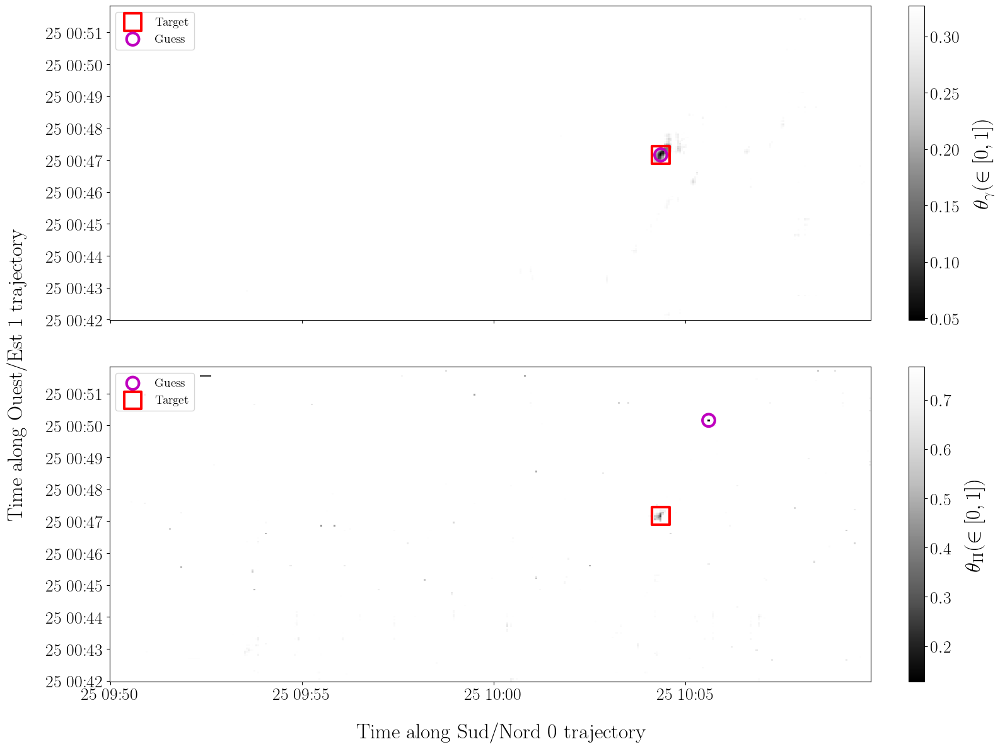

In [231]:
fig, axs = plt.subplots(nrows=2, ncols=1, figsize=(16, 12), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    src_lon1.src_datetime,
    src_lon2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")
im = axs[1].pcolormesh(
    src_lon1.src_datetime,
    src_lon2.src_datetime,
    dist_theta.T,
    cmap="Grays_r",
    vmin=np.nanmin(dist_theta),
    vmax=np.nanpercentile(dist_theta, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$\theta_{\Pi} (\in [0, 1])$")

axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)
axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)

for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

#### $\theta_{\gamma}$ vs $\theta_{\Pi}$ vs $L2_{\gamma}$

Text(0.02, 0.5, 'Time along Ouest/Est 1 trajectory')

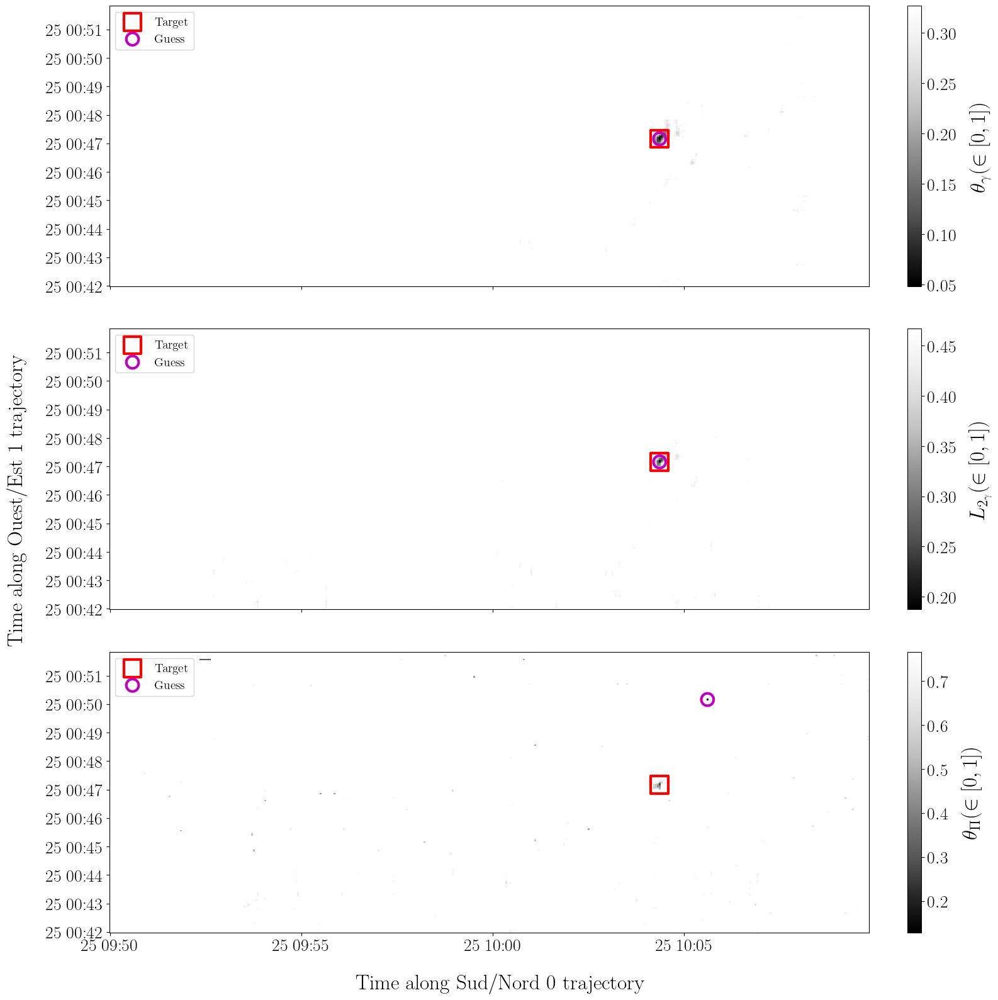

In [229]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(16, 16), sharex=True, sharey=True)
im = axs[0].pcolormesh(
    src_lon1.src_datetime,
    src_lon2.src_datetime,
    dist_theta_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta_gamma, 0.1),
    vmin=np.nanmin(dist_theta_gamma),
    vmax=np.nanpercentile(dist_theta_gamma, 0.5),
)
plt.colorbar(im, ax=axs[0], label=r"$\theta_{\gamma} (\in [0, 1])$")

im = axs[1].pcolormesh(
    src_lon1.src_datetime,
    src_lon2.src_datetime,
    dist_L2_gamma.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_L2_gamma, 0.1),
    vmin=np.nanmin(dist_L2_gamma),
    vmax=np.nanpercentile(dist_L2_gamma, 0.5),
)
plt.colorbar(im, ax=axs[1], label=r"$L_{2_{\gamma}} (\in [0, 1])$")

im = axs[2].pcolormesh(
    src_lon1.src_datetime,
    src_lon2.src_datetime,
    dist_theta.T,
    cmap="Grays_r",
    # vmin=np.nanpercentile(dist_theta, 0.1),
    vmin=np.nanmin(dist_theta),
    vmax=np.nanpercentile(dist_theta, 0.5),
)
plt.colorbar(im, ax=axs[2], label=r"$\theta_{\Pi} (\in [0, 1])$")


axs[0].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[0].scatter(
    xmin_theta_gamma,
    ymin_theta_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[1].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[1].scatter(
    xmin_L2_gamma,
    ymin_L2_gamma,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)

axs[2].scatter(
    xmin,
    ymin,
    marker="s",
    s=400,
    facecolors="none",
    edgecolors="r",
    label="Target",
    linewidth=3,
)
axs[2].scatter(
    xmin_theta,
    ymin_theta,
    marker="o",
    s=200,
    facecolors="none",
    edgecolors="m",
    label="Guess",
    linewidth=3,
)


for ax in axs.flatten():
    ax.legend(loc="upper left", fontsize=14)

fig.supxlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
fig.supylabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)

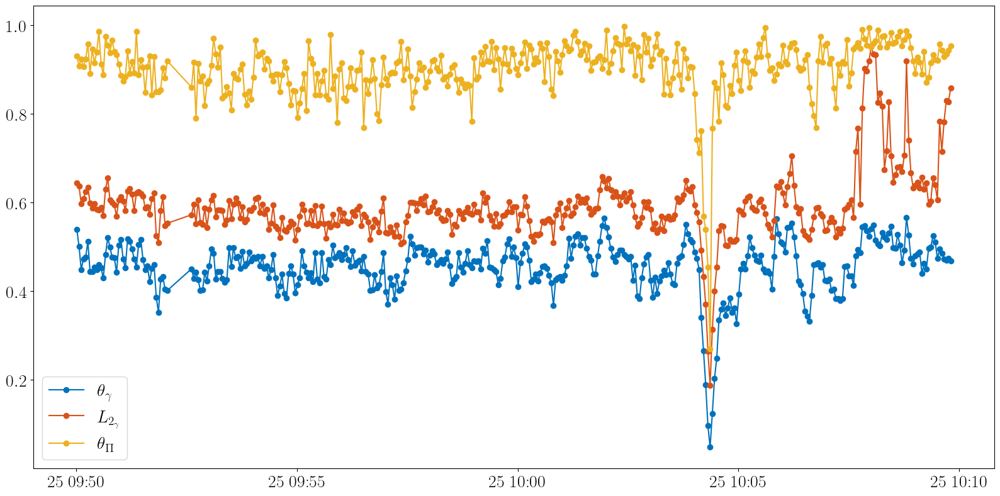

In [233]:
idx_ymin_theta_gamma = np.abs(src_lon2.src_datetime - ymin_theta_gamma).argmin(dim="src_datetime")
idx_ymin = np.abs(src_lon2.src_datetime - ymin).argmin(dim="src_datetime")
line_theta_gamma = dist_theta_gamma[:, idx_ymin]

# idx_ymin_theta = np.abs(src_lon2.src_datetime - ymin_theta).argmin(dim="src_datetime")
line_theta = dist_theta[:, idx_ymin]

# idx_ymin_L2_gamma = np.abs(src_lon2.src_datetime - ymin_L2_gamma).argmin(dim="src_datetime")
line_L2_gamma = dist_L2_gamma[:, idx_ymin]

plt.figure()
plt.plot(
    src_lon1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(src_lon1.src_datetime, line_L2_gamma, "-o", color=color(1), label=r"$L_{2_{\gamma}}$")
plt.plot(src_lon1.src_datetime, line_theta, "-o", color=color(2), label=r"$\theta_{\Pi}$")
plt.legend()

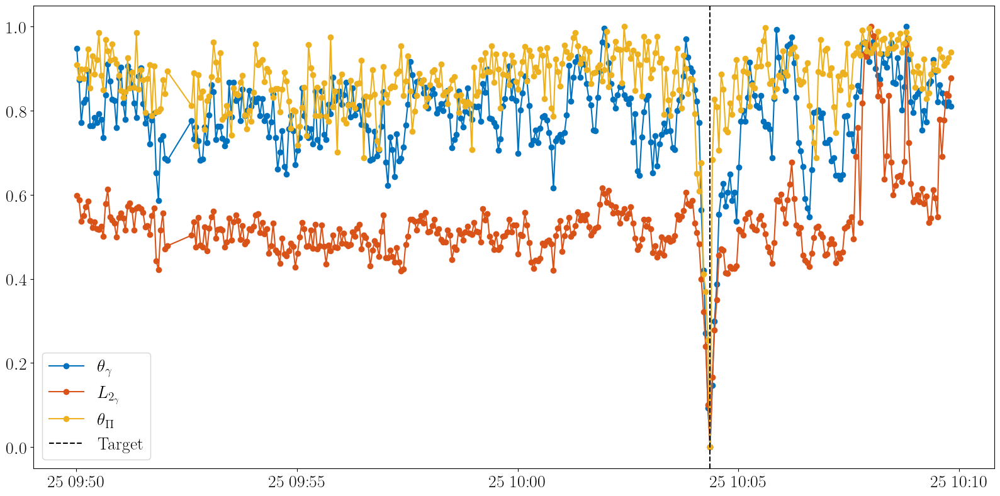

In [236]:
line_theta_gamma = (line_theta_gamma - np.nanmin(line_theta_gamma)) / (np.nanmax(line_theta_gamma) - np.nanmin(line_theta_gamma))
line_theta = (line_theta - np.nanmin(line_theta)) / (np.nanmax(line_theta) - np.nanmin(line_theta))
line_L2_gamma = (line_L2_gamma - np.nanmin(line_L2_gamma)) / (np.nanmax(line_L2_gamma) - np.nanmin(line_L2_gamma))

plt.figure()
plt.plot(
    src_lon1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    src_lon1.src_datetime,
    line_L2_gamma,
    "-o",
    color=color(1),
    label=r"$L_{2_{\gamma}}$",
)
plt.plot(
    src_lon1.src_datetime, line_theta, "-o", color=color(2), label=r"$\theta_{\Pi}$"
)
plt.axvline(xmin, color="k", linestyle="--", label="Target")
plt.legend()

Les trois distances présentent un minimum à la position attendue. Comme précédemment observé, le domaine de monotonie est très faible quelle que soit la distance ! 

(np.float64(20509.419000001133), np.float64(20509.420388890023))

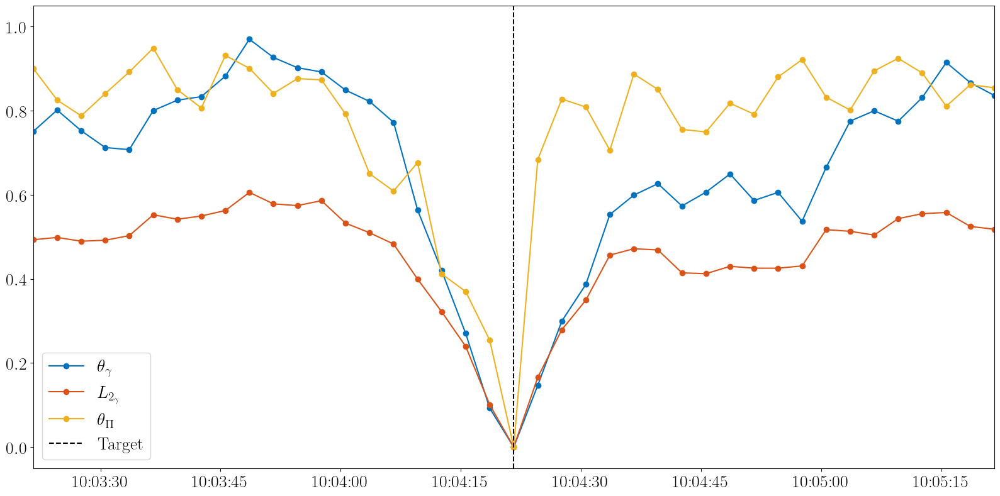

In [239]:
line_theta_gamma = (line_theta_gamma - np.nanmin(line_theta_gamma)) / (
    np.nanmax(line_theta_gamma) - np.nanmin(line_theta_gamma)
)
line_theta = (line_theta - np.nanmin(line_theta)) / (
    np.nanmax(line_theta) - np.nanmin(line_theta)
)
line_L2_gamma = (line_L2_gamma - np.nanmin(line_L2_gamma)) / (
    np.nanmax(line_L2_gamma) - np.nanmin(line_L2_gamma)
)

plt.figure()
plt.plot(
    src_lon1.src_datetime,
    line_theta_gamma,
    "-o",
    color=color(0),
    label=r"$\theta_{\gamma}$",
)
plt.plot(
    src_lon1.src_datetime,
    line_L2_gamma,
    "-o",
    color=color(1),
    label=r"$L_{2_{\gamma}}$",
)
plt.plot(
    src_lon1.src_datetime, line_theta, "-o", color=color(2), label=r"$\theta_{\Pi}$"
)
plt.axvline(xmin, color="k", linestyle="--", label="Target")
plt.legend()
plt.xlim(xmin - np.timedelta64(60, "s"), xmin + np.timedelta64(60, "s"))

On dénombre seulement une dizaine de points dans le lobe principale. 

Afin de quantifier le déplacement associé à ces variations rapides de la distance dans l'espace des données on peut évaluer la vitesse de la source à l'intersection. 

In [249]:
from pyproj import Geod

geod = Geod(ellps="WGS84")

src_lon1, src_lat1 = (
    ds_feature_section1.tir_src_lon,
    ds_feature_section1.tir_src_lat,
)
src_lon2, src_lat2 = (
    ds_feature_section2.tir_src_lon,
    ds_feature_section2.tir_src_lat,
)

# Traj 1
lon1_a = src_lon1.values[:-1]
lat1_a = src_lat1.values[:-1]
lon1_b = src_lon1.values[1:]
lat1_b = src_lat1.values[1:]

_, _, dist_11 = geod.inv(lons1=lon1_a, lats1=lat1_a, lons2=lon1_b, lats2=lat1_b)

# Traj 2
lon2_a = src_lon2.values[:-1]
lat2_a = src_lat2.values[:-1]
lon2_b = src_lon2.values[1:]
lat2_b = src_lat2.values[1:]

_, _, dist_22 = geod.inv(lons1=lon2_a, lats1=lat2_a, lons2=lon2_b, lats2=lat2_b)

Text(0, 0.5, 'Distance between consecutive positions')

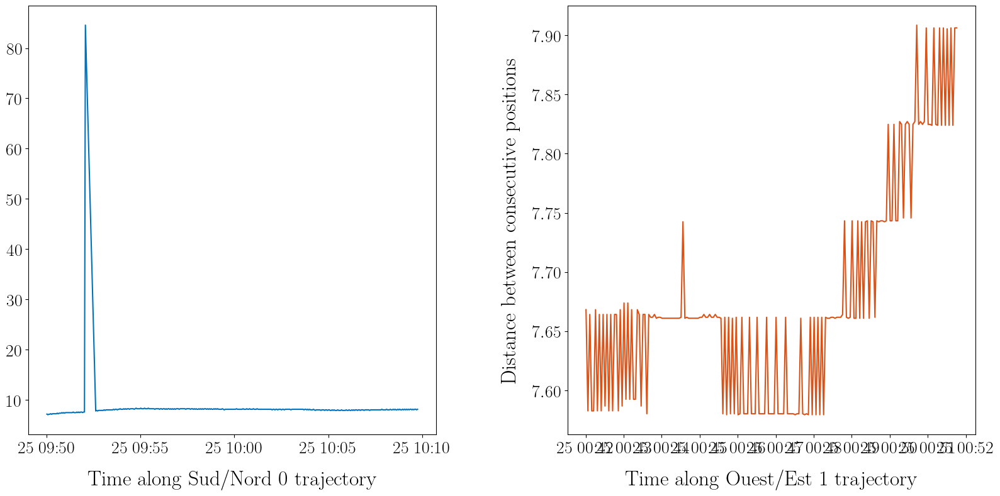

In [253]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

im = axs[0].plot(src_lon1.src_datetime[:-1], dist_11, color=color(0))
im = axs[1].plot(src_lon2.src_datetime[:-1], dist_22, color=color(1))

axs[0].set_xlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
axs[1].set_xlabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)
plt.ylabel(
    "Distance between consecutive positions"
)

In [255]:
speed_1 = dist_11 / np.diff(src_lon1.src_datetime.values).astype("timedelta64[s]").astype(float)
speed_2 = dist_22 / np.diff(src_lon2.src_datetime.values).astype("timedelta64[s]").astype(float)

Mean speed along Sud/Nord 0 trajectory: 2.67 m/s
Mean speed along Ouest/Est 1 trajectory: 2.56 m/s


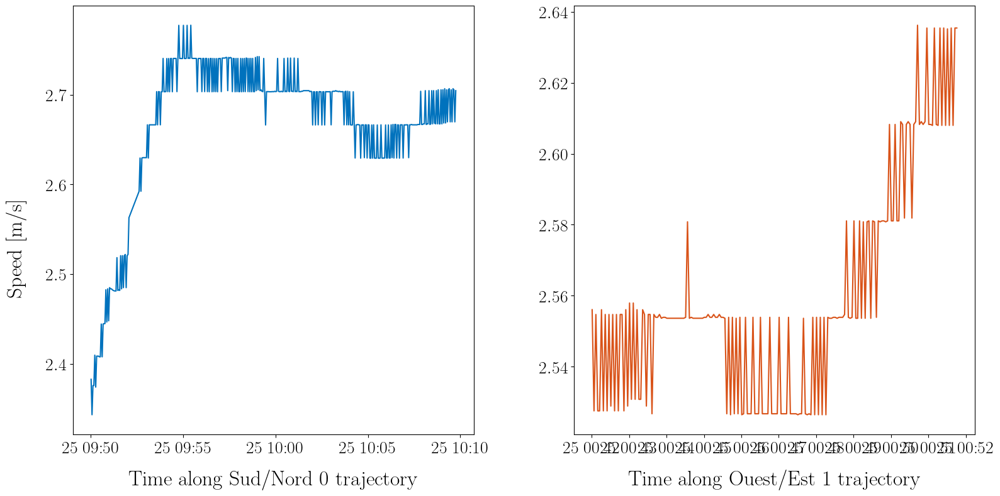

In [258]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(16, 8))

im = axs[0].plot(src_lon1.src_datetime[:-1], speed_1, color=color(0))
im = axs[1].plot(src_lon2.src_datetime[:-1], speed_2, color=color(1))

axs[0].set_xlabel(
    f"Time along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory"
)
axs[1].set_xlabel(
    f"Time along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory"
)
fig.supylabel("Speed [m/s]")

print(f"Mean speed along {ds_feature_section1.section_orientation} {ds_feature_section1.section_id} trajectory: {np.nanmean(speed_1):.2f} m/s")
print(f"Mean speed along {ds_feature_section2.section_orientation} {ds_feature_section2.section_id} trajectory: {np.nanmean(speed_2):.2f} m/s")

La vitesse moyenne de la source est identique sur les deux trajectoires $\approx$ 2.6 m/s. L'intervalle inter-tir est de 3 s, pour 10 tirs on a donc un déplacement d'environ 25 m. 